# 07 · Web 后端实战（部门管理）


来源：[飞书讲义《07-Web后端实战》](https://heuqqdmbyk.feishu.cn/wiki/VT2ewTC7Zi9hiikrZuVcUbJMnog)及附属 [《406问题解决方案》](https://heuqqdmbyk.feishu.cn/wiki/Kdngw2Fp4iJeUnkhcTQcAhPNnUc)。整理日期：2026-09-28。

正文沿讲义顺序，保留原文、44 段原代码、52 张配图和 1 张嵌入表格；就近添加勘误及必要说明。原讲义代码展示的是逐步完善的同一项目，存在局部片段和前后版本，不能整章直接拼接成一套类。第 8、9 节提供与课程接口一致的独立跟练项目及验证顺序；第 10 节附上 406 排错资料并指出原文结论的适用边界。

配图已内嵌，可离线阅读。代码应在 Java 工程、MySQL 客户端或 Apifox 中分别使用，不在 Notebook 的 Python 内核执行。课程推广内容未收录。


## 本章学习路线（补充）

第 06 章只到 Java 调用 Mapper；本章把一次浏览器请求走完 Controller、Service、Mapper、数据库和响应。先固定接口契约，再逐个实现 CRUD，最后观察反向代理与日志。

| 阶段 | 要回答的问题 | 关键点 |
| --- | --- | --- |
| 协作 | 前端如何在后端未完成时开发？ | 前后端分离、接口文档、Apifox Mock |
| 路由 | 同一资源怎样区分查询、新增、修改和删除？ | REST、HTTP 方法、`@GetMapping` 等 |
| 数据 | URL、查询参数和 JSON 请求体如何绑定？ | `@PathVariable`、`@RequestParam`、`@RequestBody` |
| 持久化 | SQL 结果如何变成 Java 对象？ | MyBatis、字段映射、影响行数 |
| 联调 | `/api/depts` 如何抵达 `/depts`？ | Nginx 反向代理、rewrite、同源请求 |
| 诊断 | 出错后如何定位到正确一层？ | HTTP 状态、应用日志、SLF4J、Logback |

```text
浏览器 / Apifox → Nginx（可选）→ Controller → Service → Mapper → MySQL
                                      ← Result JSON ←
```


## 1 前言

前面的课程中，我们已经学习了Web开发的基础知识，包括像Maven、HTTP协议、SpringBootWeb基础、IOC、DI、MySQL、JDBC、Mybatis等。 

接下来呢，我们就要进入到后端Web实战篇的学习，在实战篇中，就要将前面学习的基础知识用起来，来完成一个大的综合案例 - Tlias智能学习辅助系统。

那这个案例里面呢，包括以下功能：

- 部门管理

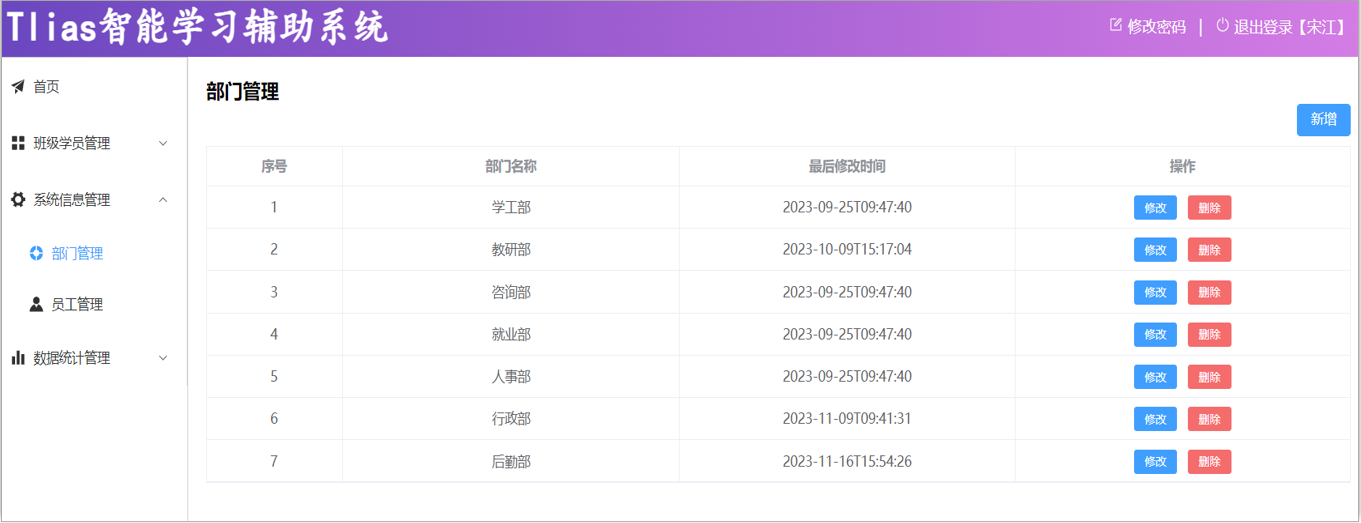

- 员工管理

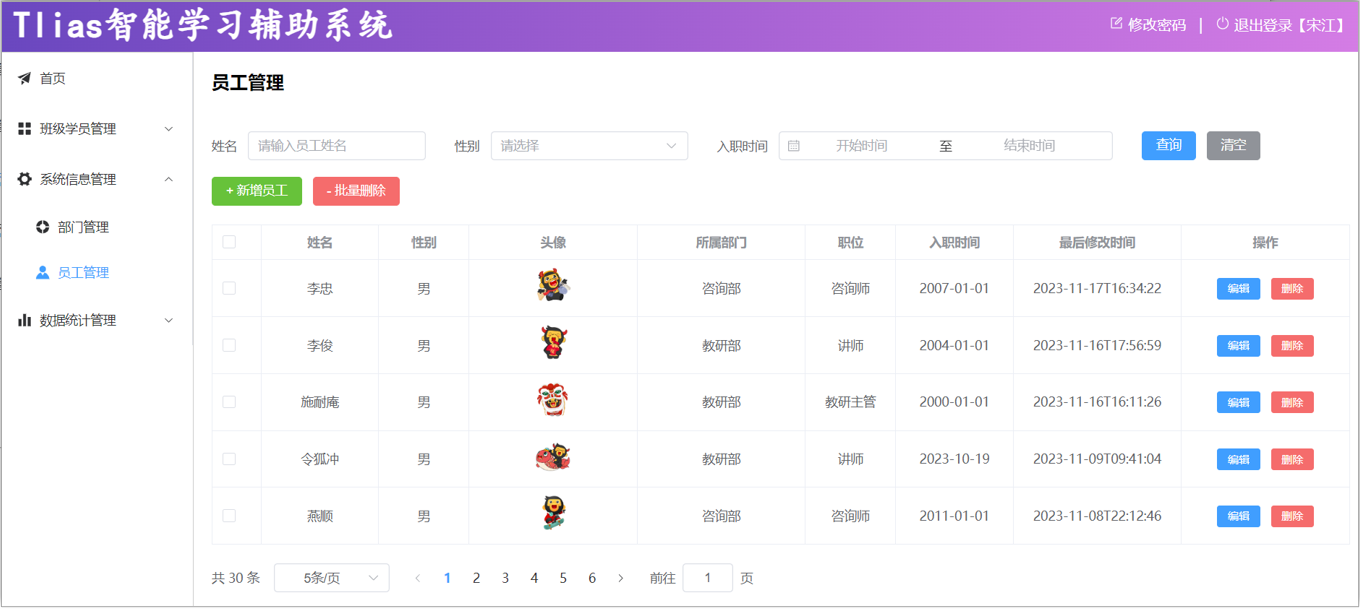

- 员工信息统计

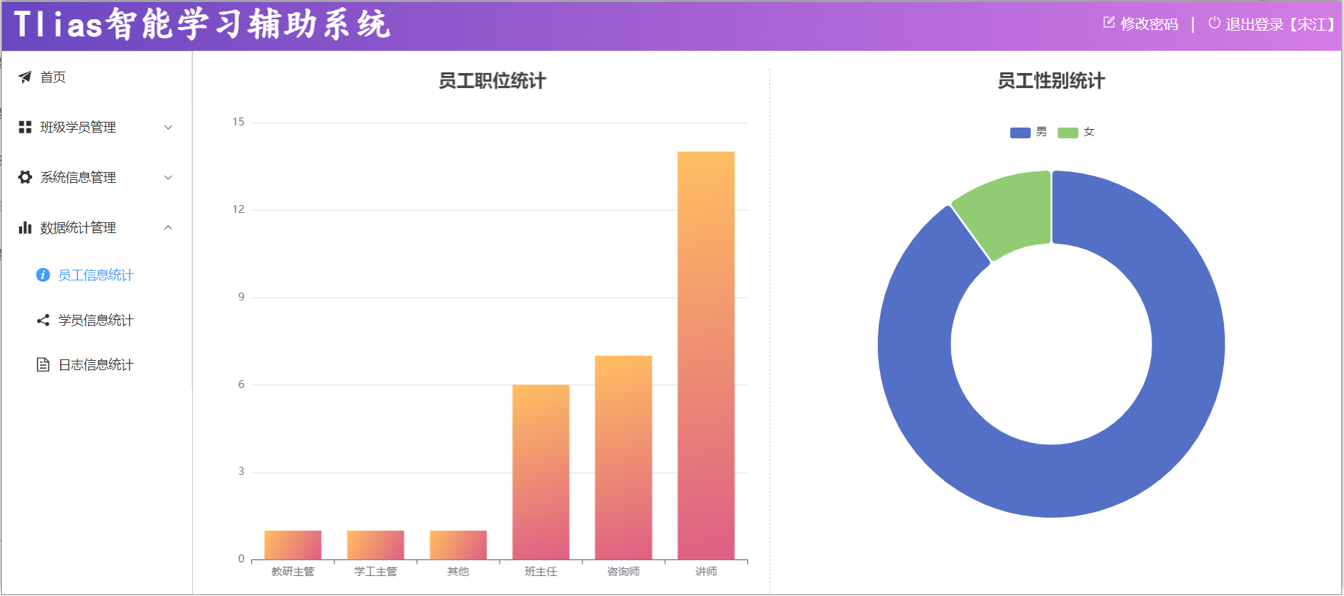

- 学员信息统计

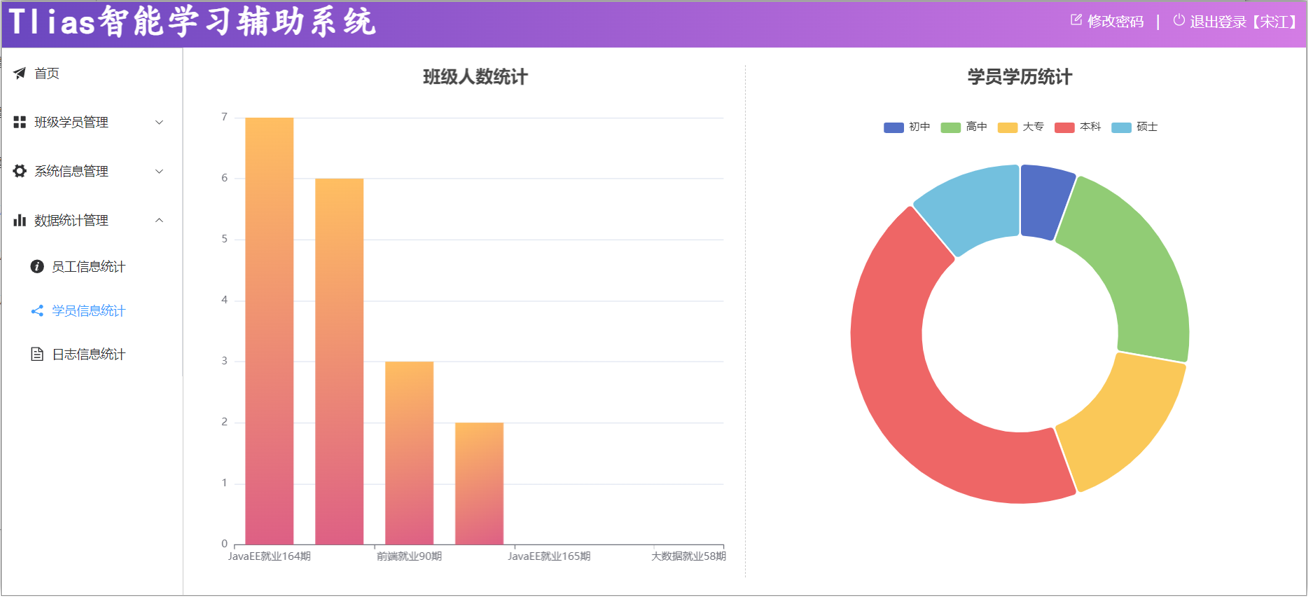

- 班级、学员管理

> <strong>在整个实战篇中，我们需要完成如下功能：</strong>
> 
> - 部门管理：查询、新增、修改、删除
> - 员工管理：
> 
>     - 查询、新增、修改、删除
>     - 文件上传
> - 报表统计
> - 登录认证
> - 日志管理
> - 班级管理（自己实战内容）
> - 学员管理（自己实战内容）

那今天呢，我们就先来完成第一个模块：部门管理。


## 2 准备工作


### 2.1 开发规范


#### 2.1.1 前后端分离开发

**补充：前后端分离的边界。**前端工程负责页面、交互和浏览器请求，后端工程负责接口、业务和数据访问；两边通过 HTTP 接口契约协作。分离不等于两个工程永远部署在两台机器上，也不等于后端只能返回 JSON。开发时可以由 Nginx 提供页面并反向代理 API，生产环境再由网关、负载均衡和多个服务实例承担同样的边界。

在之前的课程中，我们介绍过，现在的企业项目开发有2种开发模式：<strong>前后台混合开发</strong>和<strong>前后台分离开发</strong>。

前后台混合开发，顾名思义就是前台后台代码混在一起开发，如下图所示：

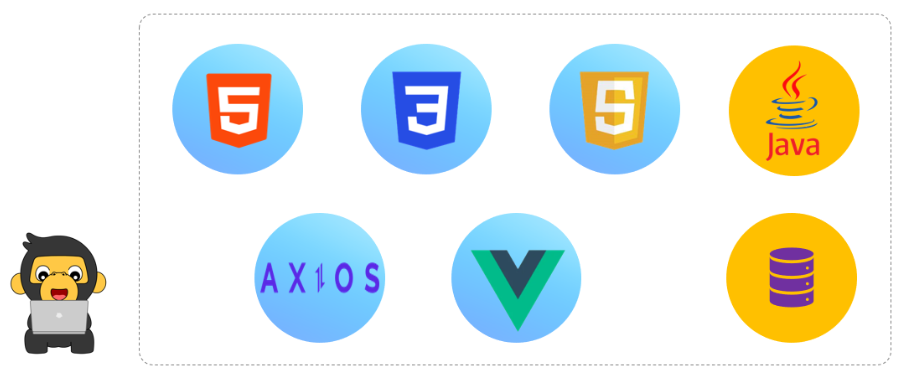

这种开发模式有如下缺点：

- 沟通成本高：后台人员发现前端有问题，需要找前端人员修改，前端修改成功，再交给后台人员使用
- 分工不明确：后台开发人员需要开发后台代码，也需要开发部分前端代码。很难培养专业人才
- 不便管理：所有的代码都在一个工程中
- 难以维护：前端代码更新，和后台无关，但是需要整个工程包括后台一起重新打包部署。

所以我们目前基本都是采用的前<strong>后台分离开发</strong>方式，如下图所示：

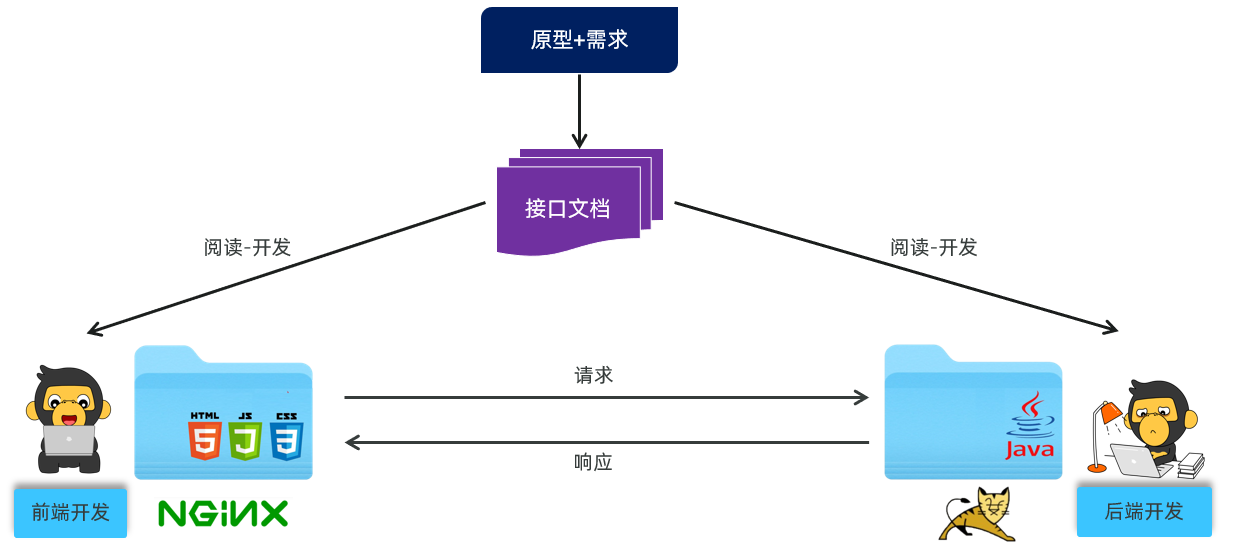

我们将原先的工程分为前端工程和后端工程这2个工程，然后前端工程交给专业的前端人员开发，后端工程交给专业的后端人员开发。

前端页面需要数据，可以通过发送异步请求，从后台工程获取。但是，我们前后台是分开来开发的，那么前端人员怎么知道后台返回数据的格式呢？后端人员开发，怎么知道前端人员需要的数据格式呢？

所以针对这个问题，我们前后台统一制定一套规范！我们前后台开发人员都需要遵循这套规范开发，这就是我们的<strong>接口</strong><strong>文档</strong>。

接口文档有离线版和在线版本，接口文档示可以查询今天提供<strong>资料/接口文档</strong>里面的资料。

那么接口文档的内容怎么来的呢？是我们后台开发者根据产品经理提供的产品原型和需求文档所撰写出来的，产品原型示例可以参考今天提供<strong>资料/页面原型</strong>里面的资料。

那么基于前后台分离开发的模式下，我们后台开发者开发一个功能的具体流程如何呢？如下图所示：

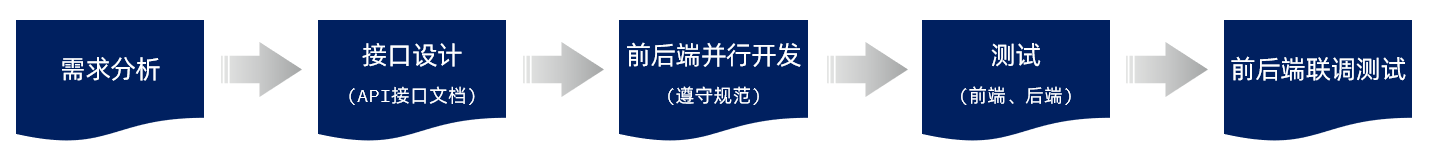

1. 需求分析：首先我们需要阅读需求文档，分析需求，理解需求。
2. 接口定义：查询接口文档中关于需求的接口的定义，包括地址，参数，响应数据类型等等
3. 前后台并行开发：各自按照接口文档进行开发，实现需求
4. 测试：前后台开发完了，各自按照接口文档进行测试
5. 前后段联调测试：前段工程请求后端工程，测试功能


#### 2.1.2 Restful风格

我们的案例是基于当前最为主流的前后端分离模式进行开发。

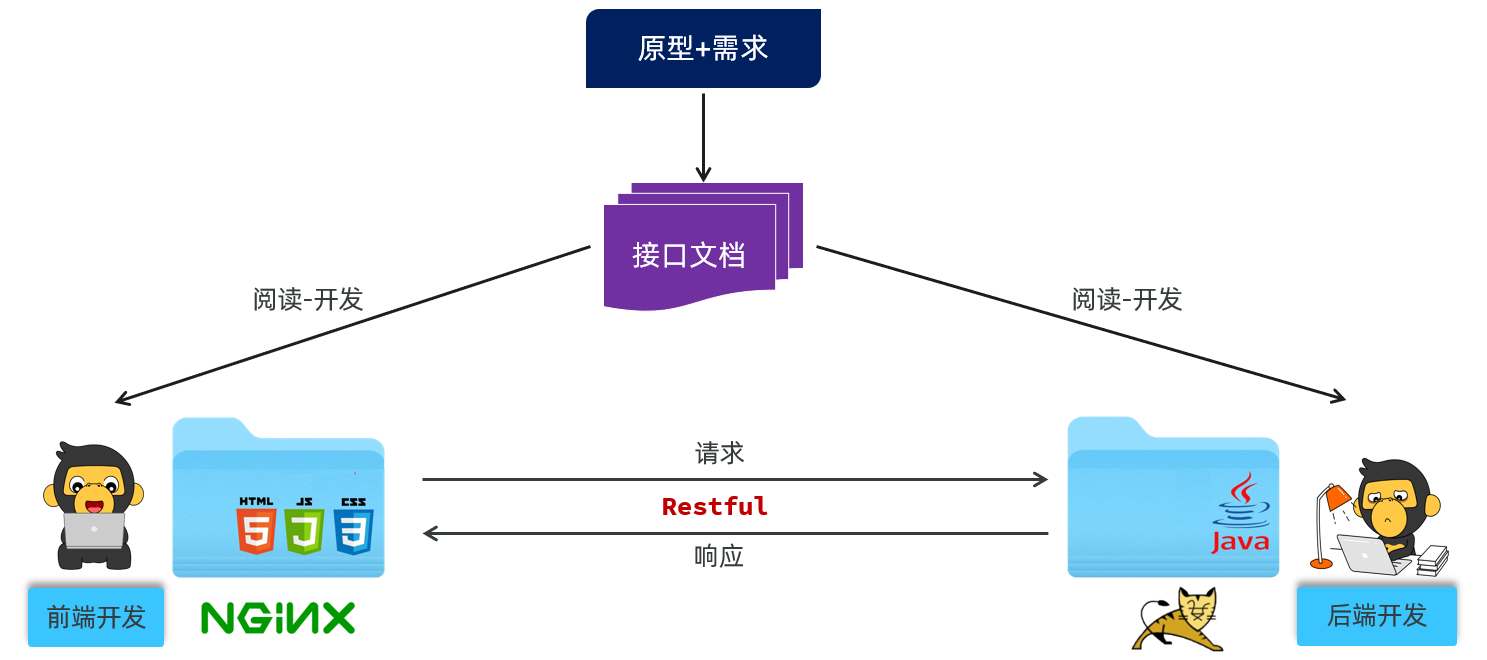

在前后端分离的开发模式中，前后端开发人员都需要根据提前定义好的接口文档，来进行前后端功能的开发。

> 后端开发人员：必须严格遵守提供的接口文档进行后端功能开发（保障开发的功能可以和前端对接）

> **补充：**接口文档是双方的契约，至少要固定请求方法、路径、参数位置和类型、Content-Type、响应结构、错误码与示例。前端和后端都应以文档为准；只改一方的字段名会导致反序列化或渲染失败。

而在前后端进行交互的时候，我们需要基于当前主流的REST风格的API接口进行交互。

<strong>什么是REST风格呢?</strong>

- REST（Representational State Transfer），表述性状态转换，它是一种软件架构风格。

<strong>传统URL风格如下：</strong>

- http://localhost:8080/user/getById?id=1      GET：查询id为1的用户
- http://localhost:8080/user/saveUser            POST：新增用户
- http://localhost:8080/user/updateUser         POST：修改用户
- http://localhost:8080/user/deleteUser?id=1  GET：删除id为1的用户

我们看到，原始的传统URL呢，定义比较复杂，而且将资源的访问行为对外暴露出来了。而且，对于开发人员来说，每一个开发人员都有自己的命名习惯，就拿根据id查询用户信息来说的，不同的开发人员定义的路径可能是这样的：<code>getById</code>，<code>selectById</code>，<code>queryById</code>，<code>loadById</code>... 。 每一个人都有自己的命名习惯，如果都按照各自的习惯来，一个项目组，几十号或上百号人，那最终开发出来的项目，将会变得难以维护，没有一个统一的标准。

<strong>基于REST风格URL如下：</strong>

- http://localhost:8080/users/1       GET：查询id为1的用户
- http://localhost:8080/users          POST：新增用户
- http://localhost:8080/users          PUT：修改用户
- http://localhost:8080/users/1       DELETE：删除id为1的用户

其中总结起来，就一句话：通过URL定位要操作的资源，通过HTTP动词(请求方式)来描述具体的操作。

在REST风格的URL中，通过四种请求方式，来操作数据的增删改查。 

- GET ：  查询
- POST ：新增
- PUT ：  修改
- DELETE ：删除

我们看到如果是基于REST风格，定义URL，URL将会<strong>更加简洁、更加规范、更加优雅</strong>。

> <strong>注意事项：</strong>
> 
> - REST是风格，是约定方式，约定不是规定，可以打破
> - 描述模块的功能通常使用复数，也就是加s的格式来描述，表示此类资源，而非单个资源。如：users、emps、books…

**REST 说明：**REST 是约定风格，不是 Spring 注解。资源名通常用复数只是团队习惯；真正需要稳定的是资源路径、HTTP 方法、状态码和响应语义。GET 应保持安全且幂等，PUT 通常按同一请求重复执行得到相同资源状态，DELETE 重复执行要明确返回 404 还是幂等成功。课程示例返回统一业务 JSON，仍可结合 HTTP 4xx/5xx 表达传输层错误。


#### 2.1.3 Apifox

我们上面讲到，在这个案例中，我们将会基于Restful风格的接口进行交互，那么其中就涉及到常见的4中请求方式，包括：POST、DELETE、PUT、GET。

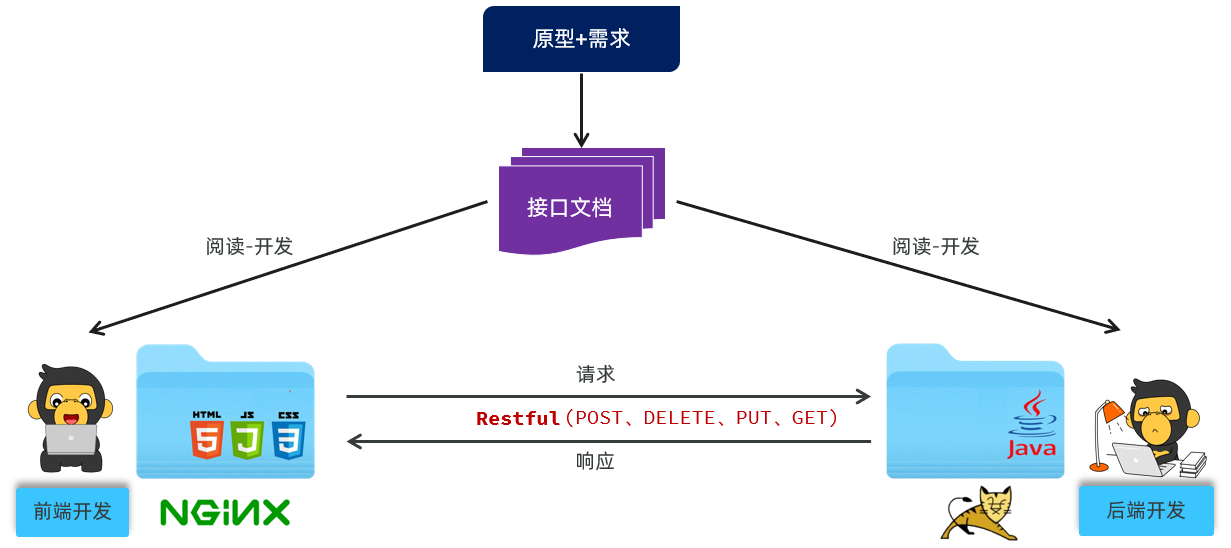

因为在浏览器地中所发起的所有的请求，都是GET方式的请求。那大家就需要思考两个问题：

> **勘误：**在浏览器地址栏直接访问 URL 通常发送 GET，但浏览器也能通过表单或 `fetch` 发送其他方法的请求。本例用 Apifox 是为了方便设置请求方法、请求头和 JSON 请求体，不是浏览器本身只能发送 GET。

- 前后端都在并行开发，后端开发完对应的接口之后，如何对接口进行请求测试呢？
- 前后端都在并行开发，前端开发过程中，如何获取到数据，测试页面的渲染展示呢？

那这里我们就可以借助一些接口测试工具，比如项：Postman、Apipost、Apifox等。

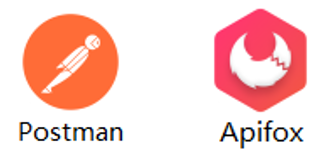

那这些工具的使用基本类似，只不过Apifox工具的功能更强强大、更加完善，所以在课程中，我们会采用功能更为强大的<strong>Apifox</strong>工具。


##### 2.1.3.1 介绍

介绍：Apifox是一款集成了Api文档、Api调试、Api Mock、Api测试的一体化协作平台。

作用：接口文档管理、接口请求测试、Mock服务。

官网： https://apifox.com/

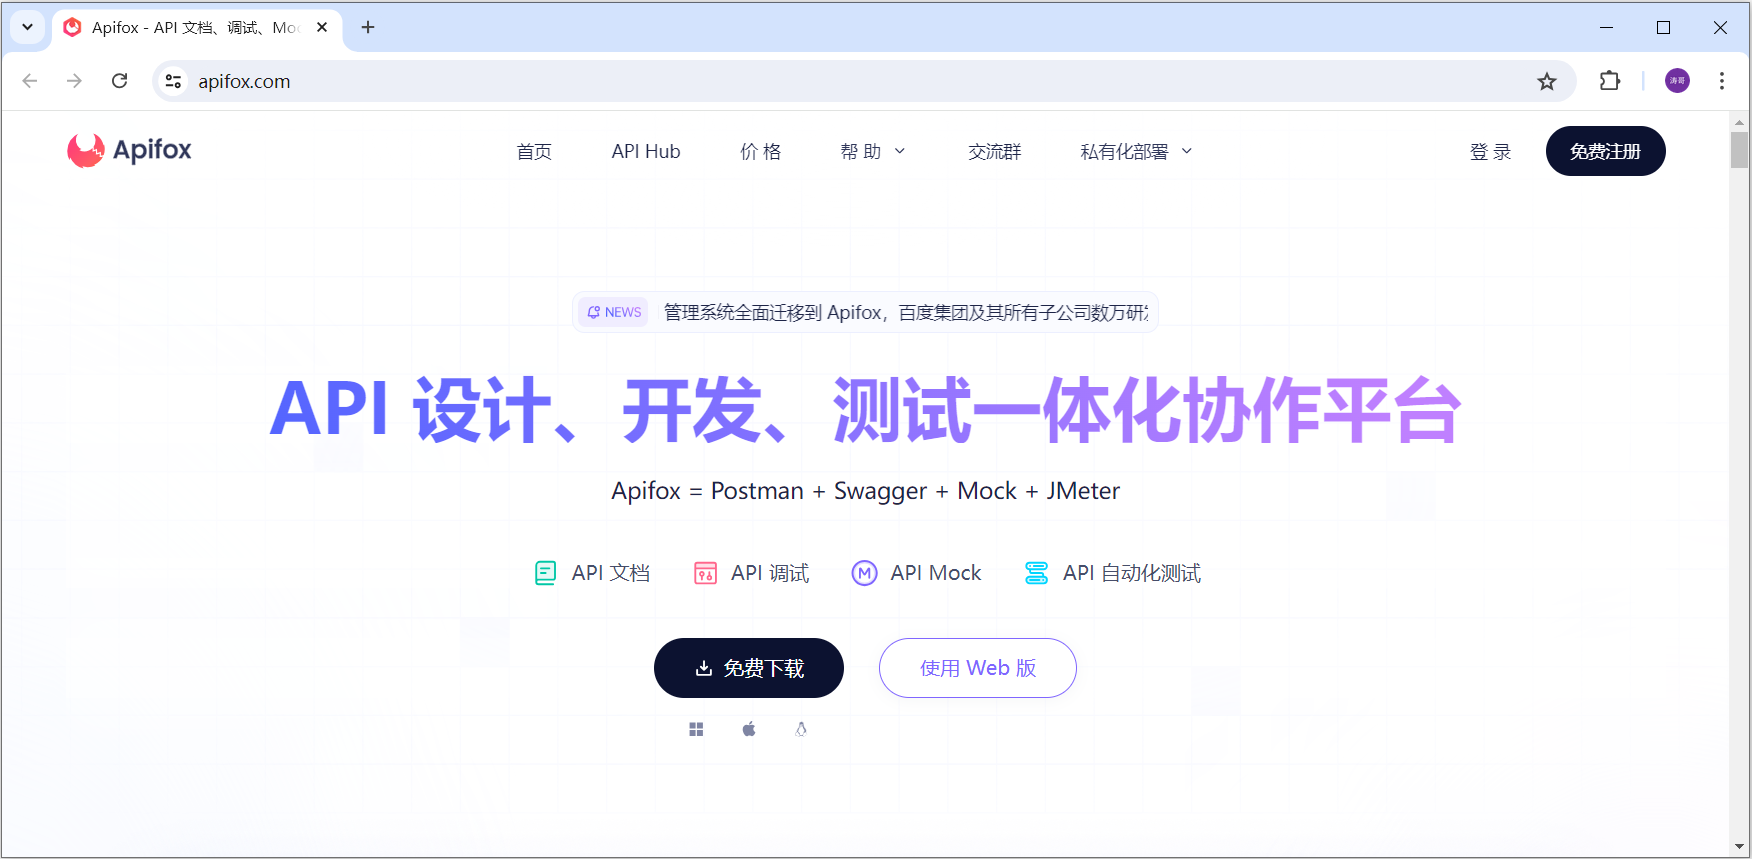


##### 2.1.3.2 安装

下载Apifox的安装包（资料中已经提供），直接双击安装 。 

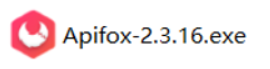

安装完成之后，就可以扫码登录Apifox，就可以使用啦。。。

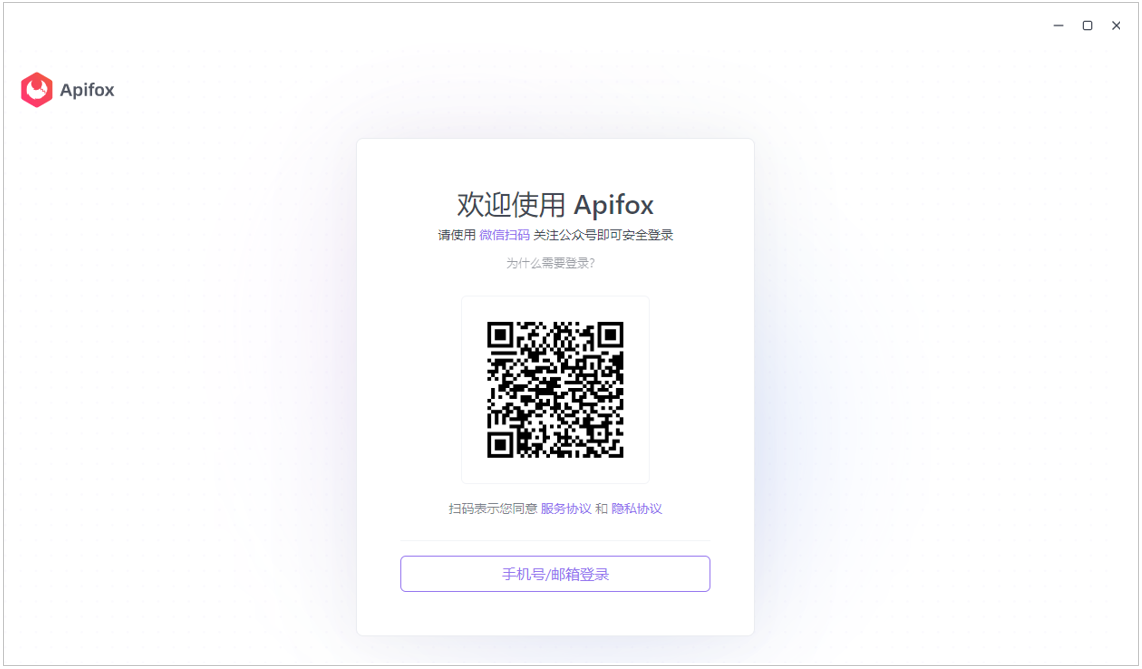

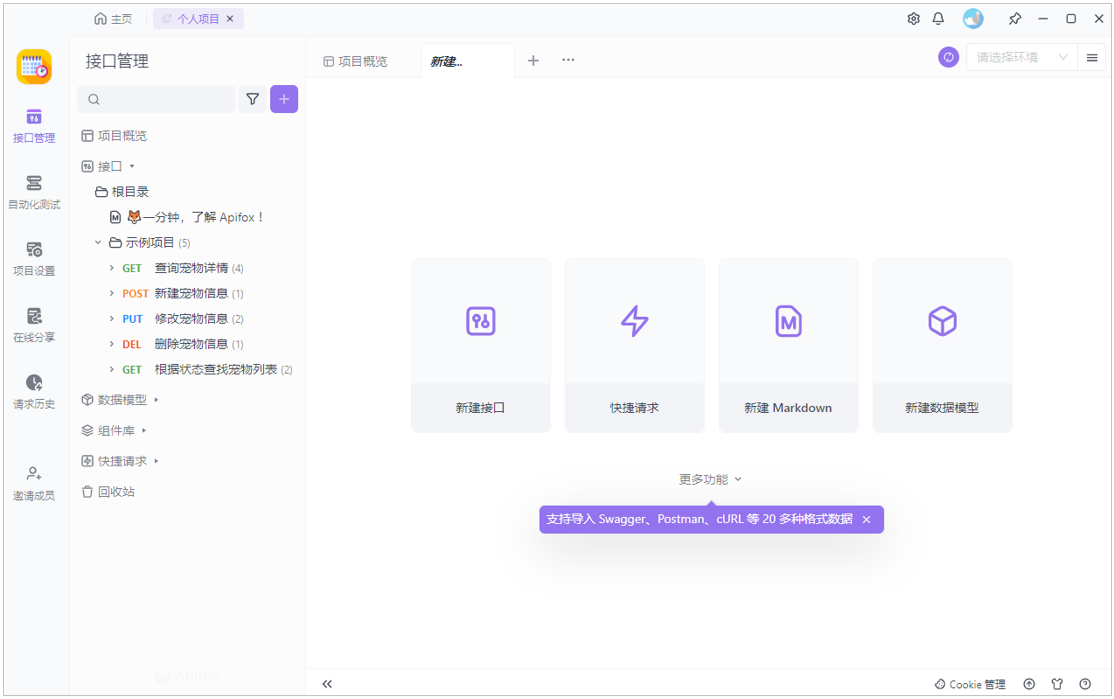


### 2.2 工程搭建

<strong>1). </strong><strong>创建SpringBoot工程，</strong><strong>并引入</strong><strong>web开发起步依赖、mybatis、mysql驱动、</strong><strong>lombok</strong><strong>。</strong>

- 创建项目

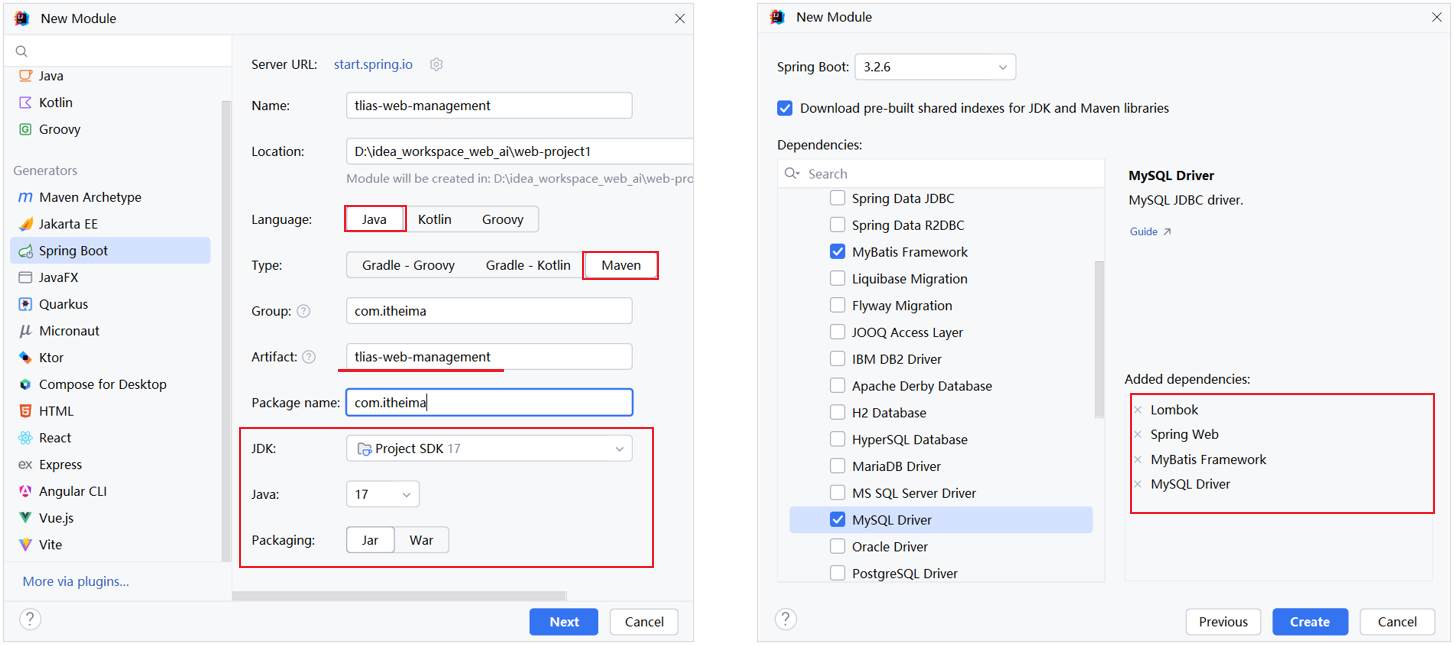

<strong>2). </strong><strong>创建数据库及对应的表结构</strong><strong>，并在application.yml中配置数据库的基本信息。</strong>

- 创建<code>tlias</code>数据库，并准备<code>dept</code>部门表。

````sql
CREATE TABLE dept (
  id int unsigned PRIMARY KEY AUTO_INCREMENT COMMENT 'ID, 主键',
  name varchar(10) NOT NULL UNIQUE COMMENT '部门名称',
  create_time datetime DEFAULT NULL COMMENT '创建时间',
  update_time datetime DEFAULT NULL COMMENT '修改时间'
) COMMENT '部门表';

INSERT INTO dept VALUES (1,'学工部','2023-09-25 09:47:40','2024-07-25 09:47:40'),
                      (2,'教研部','2023-09-25 09:47:40','2024-08-09 15:17:04'),
                      (3,'咨询部','2023-09-25 09:47:40','2024-07-30 21:26:24'),
                      (4,'就业部','2023-09-25 09:47:40','2024-07-25 09:47:40'),
                      (5,'人事部','2023-09-25 09:47:40','2024-07-25 09:47:40'),
                      (6,'行政部','2023-11-30 20:56:37','2024-07-30 20:56:37');
````

**勘误与补充：**初始化脚本依赖当前数据库已选中 `tlias`，首次运行先执行 `CREATE DATABASE tlias CHARACTER SET utf8mb4; USE tlias;`。实际建表建议显式写列清单和字符集；`INSERT INTO dept VALUES (...)` 依赖列顺序，练习中更稳妥的写法是 `INSERT INTO dept(id,name,create_time,update_time) VALUES (...)`。密码、端口和主机不要直接照抄截图，应以本机配置为准。

- 在 <code>application.yml</code> 配置文件中配置数据库的连接信息。

````yaml
spring:
  application:
    name: tlias-web-management
  #mysql连接配置
  datasource:
    driver-class-name: com.mysql.cj.jdbc.Driver
    url: jdbc:mysql://localhost:3306/tlias
    username: root
    password: 1234
mybatis:
  configuration:
    log-impl: org.apache.ibatis.logging.stdout.StdOutImpl
````

> **配置提醒：**`localhost:3306/tlias`、`root`、`1234` 是课程示例。数据库密码不要提交到 Git，建议使用环境变量或本地 profile。`mybatis.configuration.log-impl=StdOutImpl` 只适合学习观察 SQL，生产项目使用统一日志配置并避免记录敏感参数。

<strong>3). 准备基础包结构，并引入实体类Dept及统一的响应结果封装类Result</strong>

- 准备基础包结构

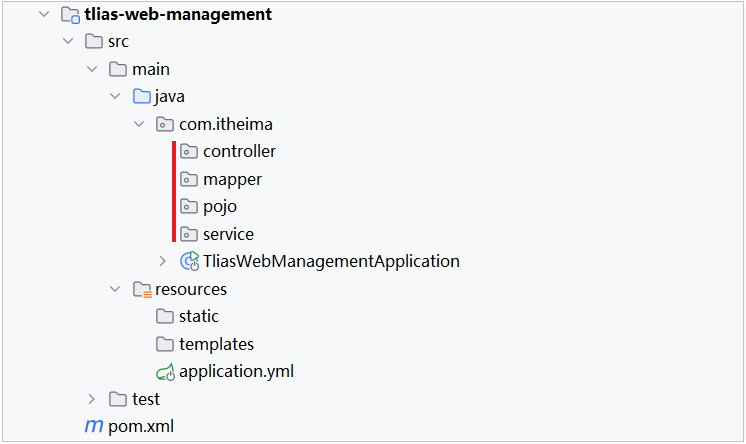

<strong> </strong>

- 实体类Dept

````java
package com.itheima.pojo;

import lombok.AllArgsConstructor;
import lombok.Data;
import lombok.NoArgsConstructor;

import java.time.LocalDateTime;

@Data
@NoArgsConstructor
@AllArgsConstructor
public class Dept {
    private Integer id;
    private String name;
    private LocalDateTime createTime;
    private LocalDateTime updateTime;
}
````

> **补充：**`LocalDateTime` 表示不带时区的本地日期时间。数据库时区、JVM 时区和 JSON 展示时区需要在项目中统一约定；跨时区系统可考虑 `Instant` 或显式时区。字段名 `create_time` / `update_time` 依赖 MyBatis 的下划线转驼峰映射或结果映射配置。

- 统一响应结果Result

````java
package com.itheima.pojo;

import lombok.Data;
import java.io.Serializable;

/**
 * 后端统一返回结果
 */
@Data
public class Result {

    private Integer code; //编码：1成功，0为失败
    private String msg; //错误信息
    private Object data; //数据

    public static Result success() {
        Result result = new Result();
        result.code = 1;
        result.msg = "success";
        return result;
    }

    public static Result success(Object object) {
        Result result = new Result();
        result.data = object;
        result.code = 1;
        result.msg = "success";
        return result;
    }

    public static Result error(String msg) {
        Result result = new Result();
        result.msg = msg;
        result.code = 0;
        return result;
    }

}
````

**改进建议：**课程的 `Result.data` 使用 `Object` 便于入门，但大型项目可改为泛型 `Result<T>`，减少调用方强制转换。错误消息不要把数据库异常、SQL 或内部堆栈直接返回给前端；统一异常处理器负责记录内部详情并返回安全提示。HTTP 成功与业务 `code=1` 是两层语义，团队要保持一致。

- 基础代码结构

    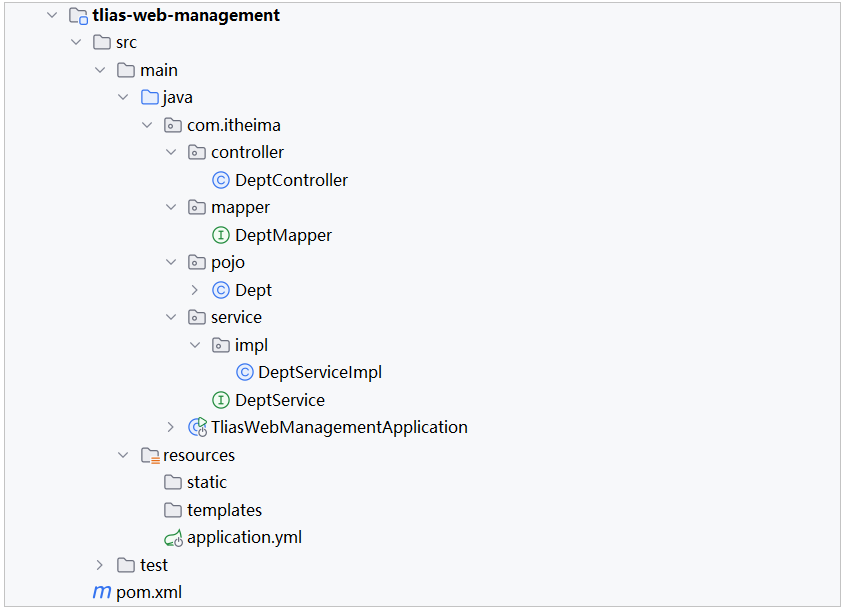

    - DeptMapper

    ````java
    package com.itheima.mapper;

    import org.apache.ibatis.annotations.Mapper;

    @Mapper
    public interface DeptMapper {
    }
    ````

    - DeptService

    ````java
    package com.itheima.service;

    public interface DeptService {
    }
    ````

    - DeptServiceImpl

    ````java
    package com.itheima.service.impl;

    import com.itheima.service.DeptService;
    import org.springframework.stereotype.Service;

    @Service
    public class DeptServiceImpl implements DeptService {
    }
    ````

    - DeptController

    ````java
    package com.itheima.controller;

    import org.springframework.web.bind.annotation.RestController;

    /**
     * 部门管理控制器
     */
    @RestController
    public class DeptController {
    }
    ````


## 3 查询部门


### 3.1 基本实现


#### 3.1.1 需求

查询所有的部门数据，查询出来展示在部门管理的页面中。页面原型效果如下：

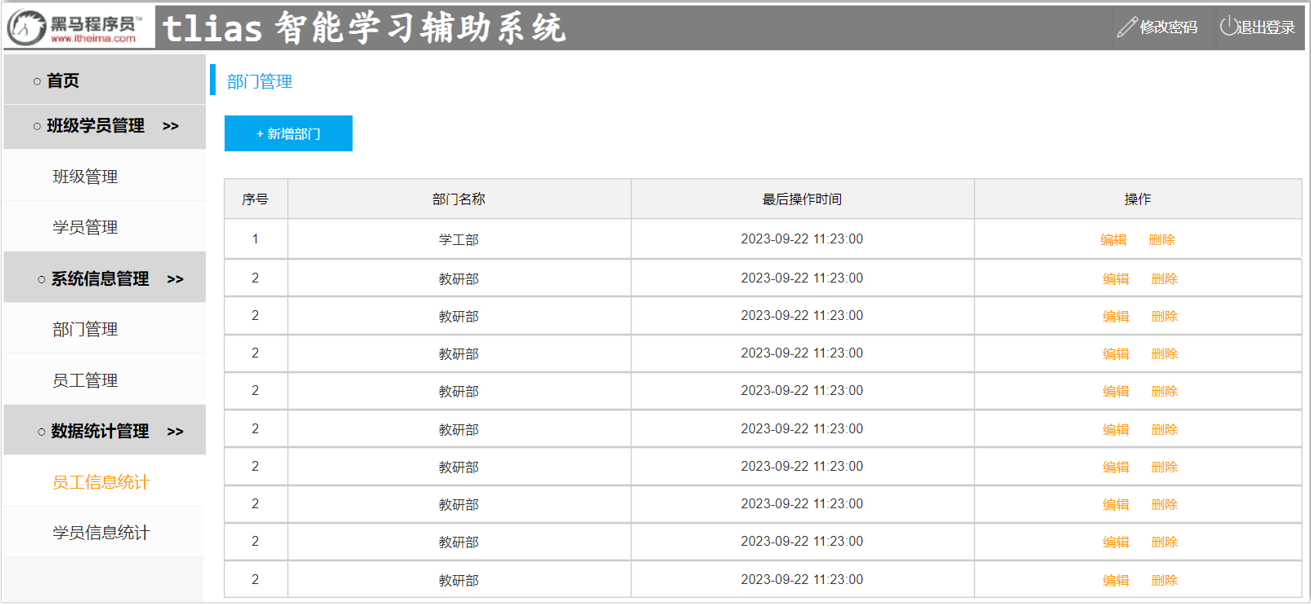


#### 3.1.2 接口描述

参照课程资料中提供的接口文档。 <code>部门管理</code> -&gt; <code>部门列表查询</code>


#### 3.1.3 实现思路

明确了删除部门的需求之后，再来梳理一下实现该功能时，三层架构每一层的职责:

> **勘误：**这里正在分析“查询部门”，原文的“删除部门”是笔误；查询流程应是 Controller → Service → Mapper → SELECT。

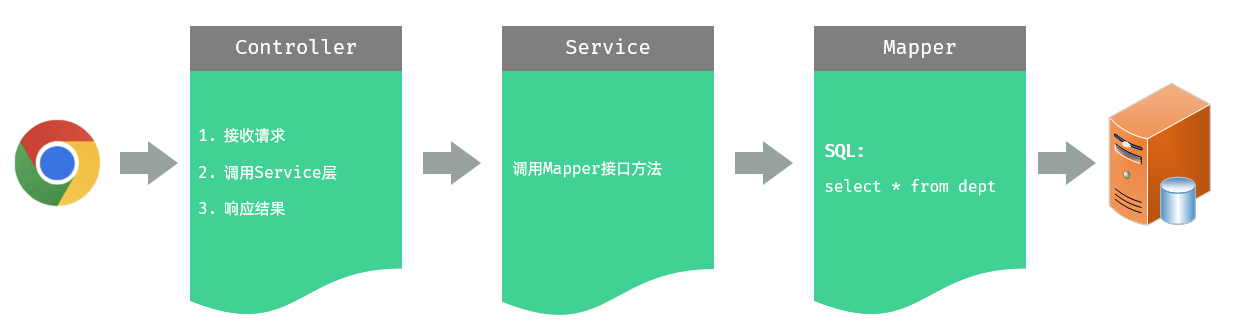

- Controller层，负责接收前端发起的请求，并调用service查询部门数据，然后响应结果。
- Service层，负责调用Mapper接口方法，查询所有部门数据。
- Mapper层，执行查询所有部门数据的操作。


#### 3.1.4 代码实现

<strong>1). Controller层</strong>

在 <code>DeptController</code> 中，增加 <code>list</code> 方法，代码如下：

````java
/**
 * 部门管理控制器
 */
@RestController
public class DeptController {

    @Autowired
    private DeptService deptService;

    /**
     * 查询部门列表
     */
    @RequestMapping("/depts")
    public Result list(){
        List<Dept> deptList = deptService.findAll();
        return Result.success(deptList);
    }
}
````

<strong>2). Service层</strong>

在 <code>DeptService</code> 中，增加 <code>findAll</code>方法，代码如下：

````java
public interface DeptService {
    /**
     * 查询所有部门
     */
    public List<Dept> findAll();
}
````

在 <code>DeptServiceImpl</code> 中，增加 <code>findAll</code>方法，代码如下：

````java
@Service
public class DeptServiceImpl implements DeptService {
    
    @Autowired
    private DeptMapper deptMapper;

    public List<Dept> findAll() {
        return deptMapper.findAll();
    }
}
````

<strong>3). Mapper层</strong>

在 <code>DeptMapper</code> 中，增加 <code>findAll</code>方法，代码如下：

````java
@Mapper
public interface DeptMapper {
    /**
     * 查询所有部门
     */
    @Select("select * from dept")
    public List<Dept> findAll();
    
}
````

> **补充：**`select *` 会让结果依赖表结构和列顺序，生产 Mapper 更推荐列出实际需要的列。`@Select` 查询返回 `LocalDateTime` 时，MyBatis 会依赖 JDBC 类型和 Java 类型处理器；字段与属性名不一致时要配置映射。


#### 3.1.5 接口测试

启动项目，然后我们就可以打开Apifox进行测试了。

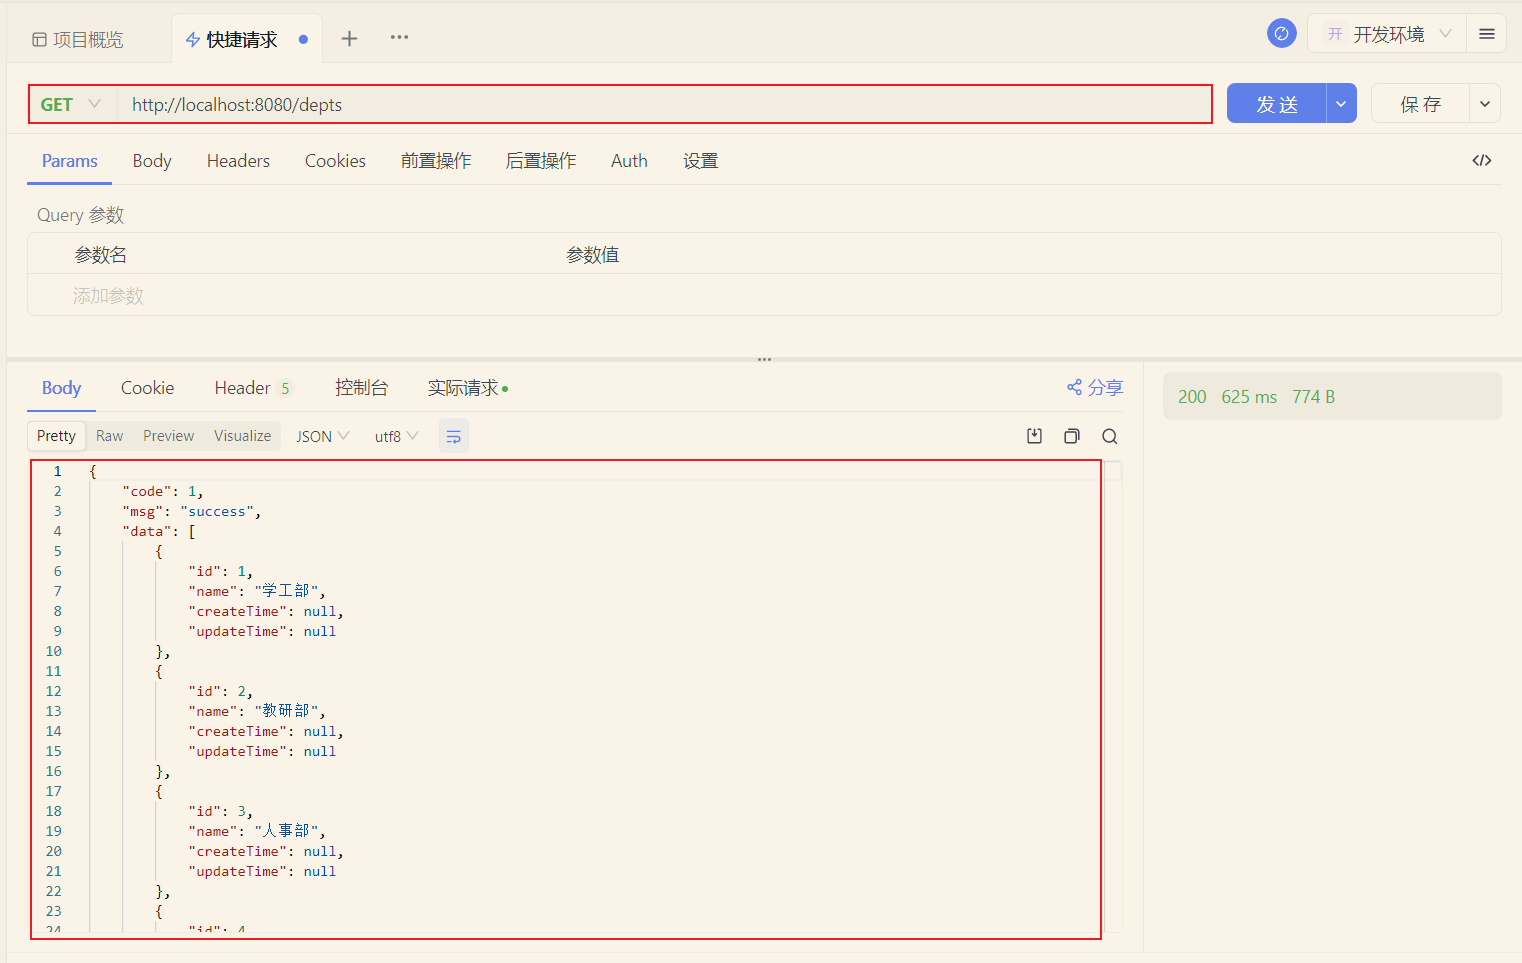

我们发现，已经查询出了所有的部门数据，并且响应回来的就是json格式的数据，与接口文档一致。 那接下来，我们再来测试一下，这个查询操作，我们使用post、put、delete方式来请求，是否可以获取到数据。

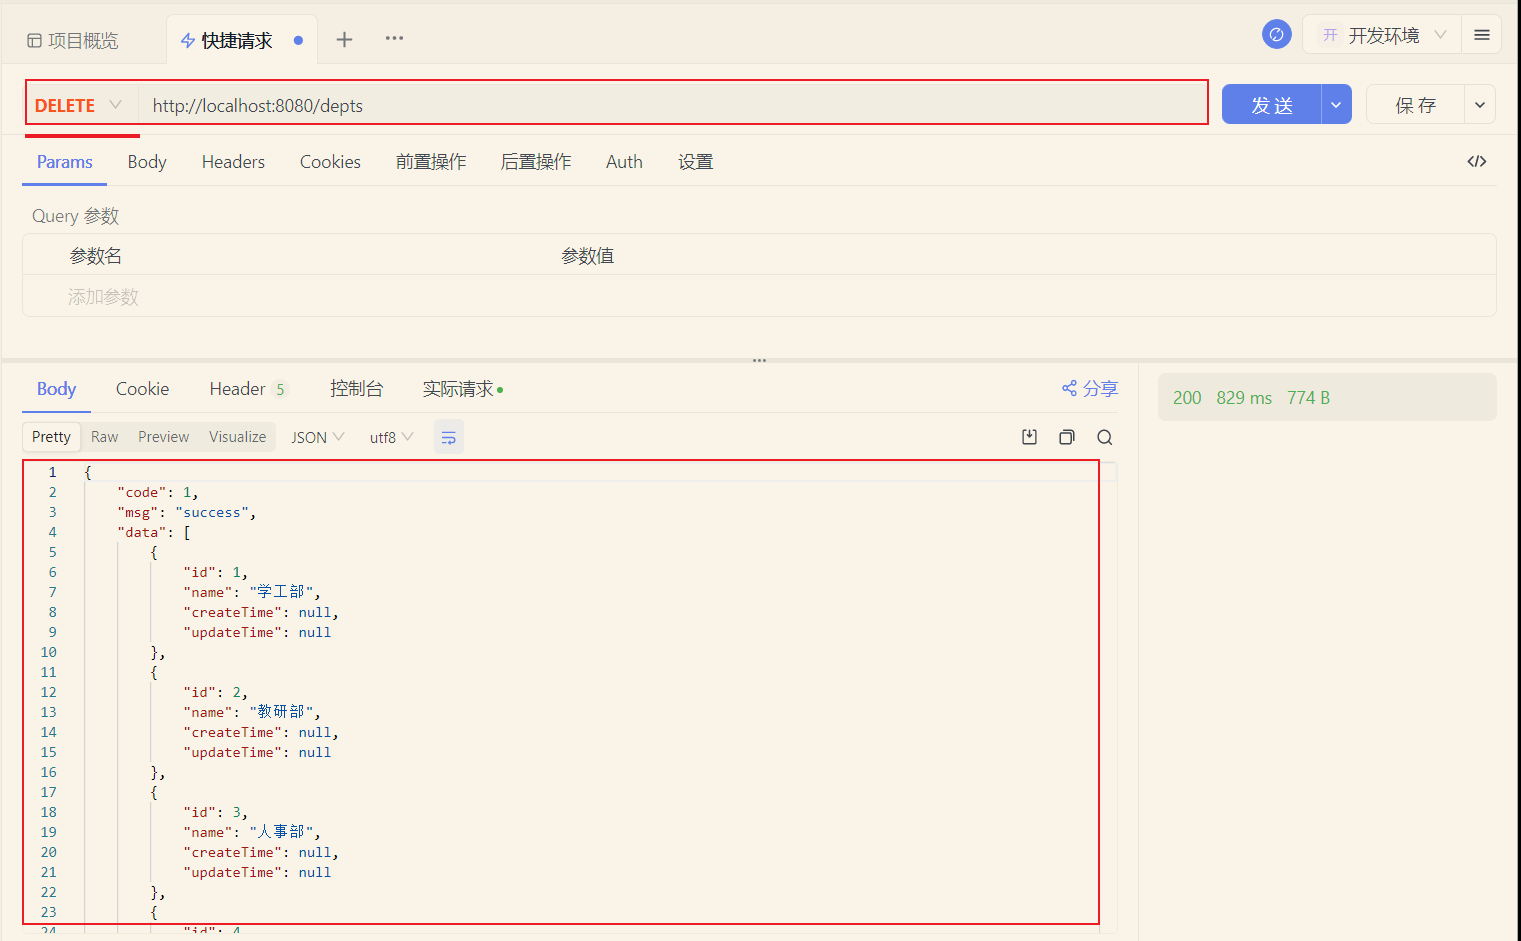

经过测试，我们发现，现在我们其实是可以通过任何方式的请求来访问查询部门的这个接口的。 而在接口文档中，明确要求该接口的请求方式为GET，那么如何限制请求方式呢？

- 方式一：在controller方法的@RequestMapping注解中通过method属性来限定。

````java
@RestController
public class DeptController {

    @Autowired
    private DeptService deptService;

    /**
     * 查询部门列表
     */
    @RequestMapping(value = "/depts", method = RequestMethod.GET)
    public Result list(){
        List<Dept> deptList = deptService.findAll();
        return Result.success(deptList);
    }
}
````

**勘误：**示例用 `@RequestMapping` 未限定方法时，GET、POST、PUT、DELETE 都可能命中同一个方法。接口文档要求 GET 时应使用 `@GetMapping`（或明确 `method = RequestMethod.GET`），并在 Apifox 验证其他方法得到 405/不匹配，而不是把所有请求都当作查询成功。

- 方式二：在controller方法上使用，@RequestMapping的衍生注解 @GetMapping。 该注解就是标识当前方法，必须以GET方式请求。

````java
@RestController
public class DeptController {

    @Autowired
    private DeptService deptService;

    /**
     * 查询部门列表
     */
    @GetMapping("/depts")
    public Result list(){
        List<Dept> deptList = deptService.findAll();
        return Result.success(deptList);
    }
}
````

> 上述两种方式，在项目开发中，推荐使用第二种方式，简洁、优雅。 
> 
> - GET方式：@GetMapping
> - POST方式：@PostMapping
> - PUT方式：@PutMapping
> - DELETE方式：@DeleteMapping

> **补充：**衍生注解的价值是把 HTTP 方法直接写进路由定义。类上有 `@RequestMapping("/depts")` 时，方法写 `@GetMapping` 即可；若方法又写 `/depts`，最终路径会重复成 `/depts/depts`，需要统一一种写法。


#### 3.1.6 数据封装

在上述测试中，我们发现部门的数据中，id、name两个属性是有值的，但是createTime、updateTime两个字段值并未成功封装，而数据库中是有对应的字段值的，这是为什么呢？ 

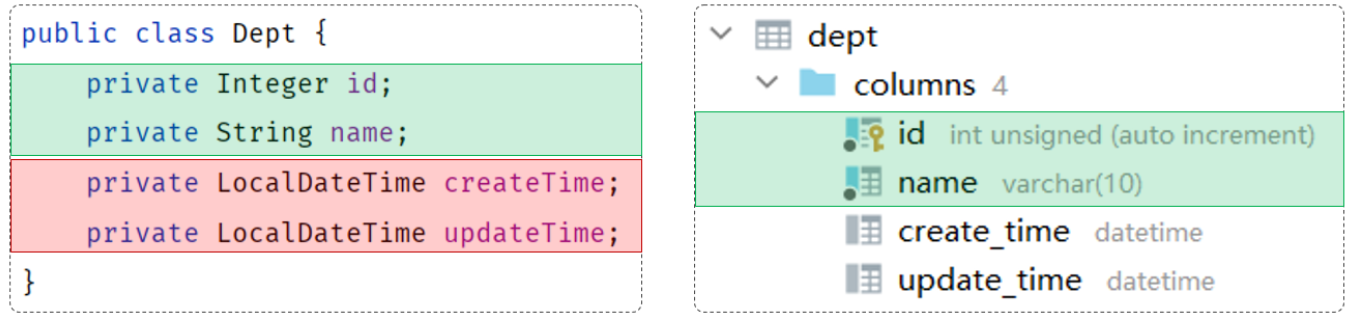

**字段映射要点：**MyBatis 默认按列名与属性名匹配。`create_time` 与 `createTime` 不相等，所以 `select *` 时可能只有 id、name 有值。三种解决方式各有边界：

| 方式 | 适用 | 风险 |
| --- | --- | --- |
| `@Results/@Result` | 单个复杂查询 | 映射分散在注解，SQL 长时难读 |
| SQL 别名 | 查询列少、一次性结果 | 每条 SQL 都要重复别名 |
| `map-underscore-to-camel-case` | 全项目遵守下划线/驼峰约定 | 不覆盖完全不相关的命名 |

开启驼峰后仍需让字段满足 `abc_xyz → abcXyz`；它不会把任意名称自动猜成正确属性。

原因如下： 

- 实体类属性名和数据库表查询返回的字段名一致，mybatis会自动封装。
- 如果实体类属性名和数据库表查询返回的字段名不一致，不能自动封装。

 解决方案：

- 手动结果映射
- 起别名
- 开启驼峰命名

<strong>1). </strong><strong>手动</strong><strong>结果映射</strong>

在DeptMapper接口方法上，通过 @Results及@Result 进行手动结果映射。

````java
@Results({@Result(column = "create_time", property = "createTime"),
          @Result(column = "update_time", property = "updateTime")})
@Select("select id, name, create_time, update_time from dept")
public List<Dept> findAll();
````

> **补充：**`@Results` 可以设置 `id = true`、`jdbcType`、`javaType` 等属性；本例只需两列映射。公共映射较多时，XML 的 `<resultMap>` 更易复用。结果映射解决的是列到对象属性，不负责校验请求参数。

说明：

- <code>@Results</code> 注解源码：

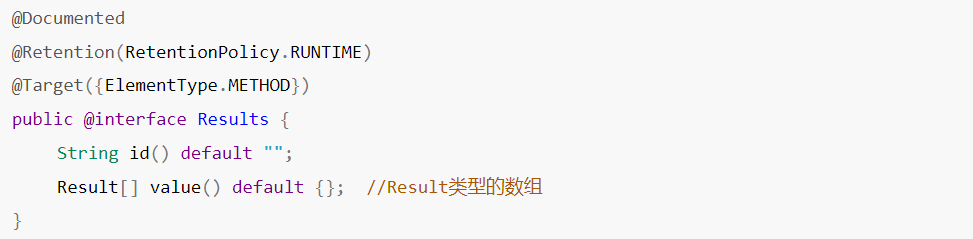

- <code>@Result</code>源代码：

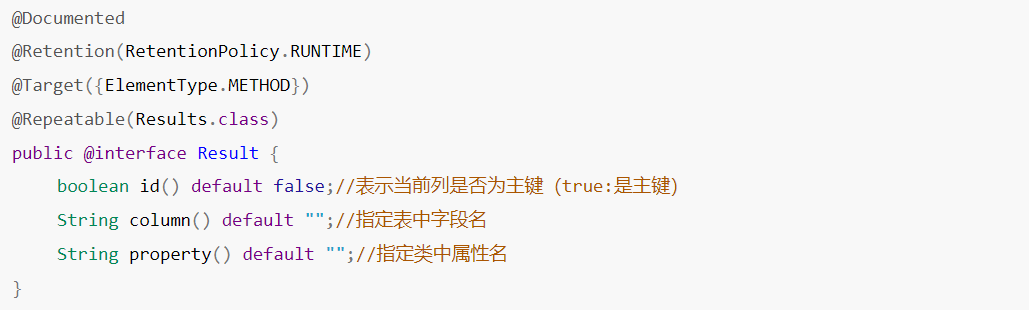

<strong>2). 起别名</strong>

在SQL语句中，对不一样的列名起别名，别名和实体类属性名一样。

````java
@Select("select id, name, create_time createTime, update_time updateTime from dept")
public List<Dept> findAll();
````

> **补充：**别名必须使用数据库返回的列标签，建议写成 `create_time AS createTime`，在不同数据库方言或开启严格模式时更清晰。只给查询结果起别名，不会修改表结构。

<strong>3). 开启驼峰命名</strong><strong>(推荐)</strong>

如果字段名与属性名符合驼峰命名规则，mybatis会自动通过驼峰命名规则映射。驼峰命名规则：   abc&#95;xyz    =&gt;   abcXyz

- 表中字段名：abc&#95;xyz
- 类中属性名：abcXyz

在application.yml中做如下配置，开启开关。

````yaml
mybatis:
  configuration:
    map-underscore-to-camel-case: true
````

> **补充：**该配置键完整名称是 `mybatis.configuration.map-underscore-to-camel-case`。YAML 缩进必须一致；开启后建议写一个包含 `create_time` 的集成测试，而不是只看 id/name 的部分成功结果。

> 要使用驼峰命名前提是 实体类的属性 与 数据库表中的字段名严格遵守驼峰命名。


### 3.2 前后端联调


#### 3.2.1 联调测试

完成了查询部门的功能，我们也通过 Apifox 工具测试通过了，下面我们再基于前后端分离的方式进行接口联调。具体操作如下：

<strong>1).</strong><strong> </strong><strong>将资料中提供的 "前端环境" 文件夹中的压缩包，拷贝到一个</strong><strong>没有中文不带空格的目录</strong><strong>下。</strong>

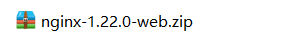

<strong>2). 解压(解压到当前目录)</strong>

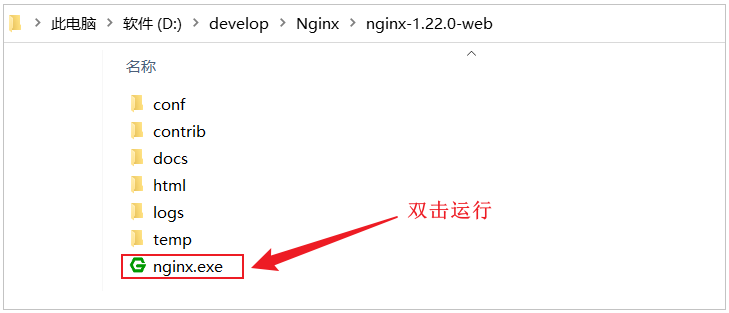

<strong>3). 双击 </strong><strong><code>nginx.exe</code></strong><strong> 启动</strong><strong>Nginx</strong><strong>，一闪而过，就说明nginx已启动完成。</strong>

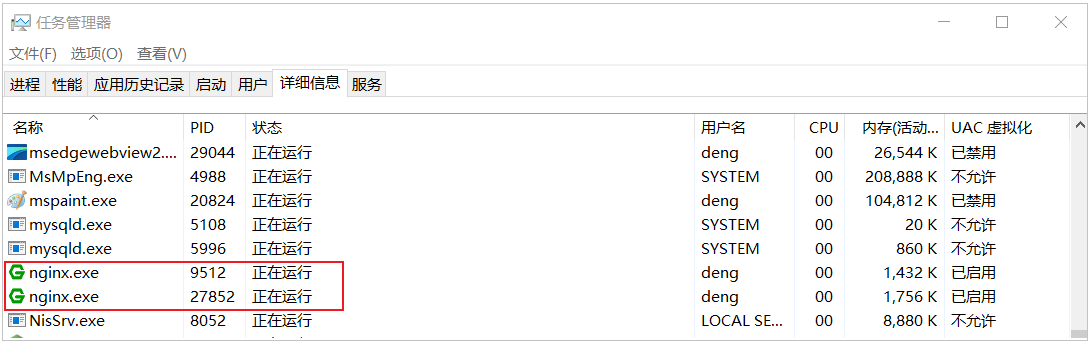

如果在任务管理器中，能看到上述两个进程，就说明nginx已经启动成功。

<strong>4). 打开浏览器，访问：</strong><a href="http://localhost:90/"><strong>http://localhost:90</strong></a>

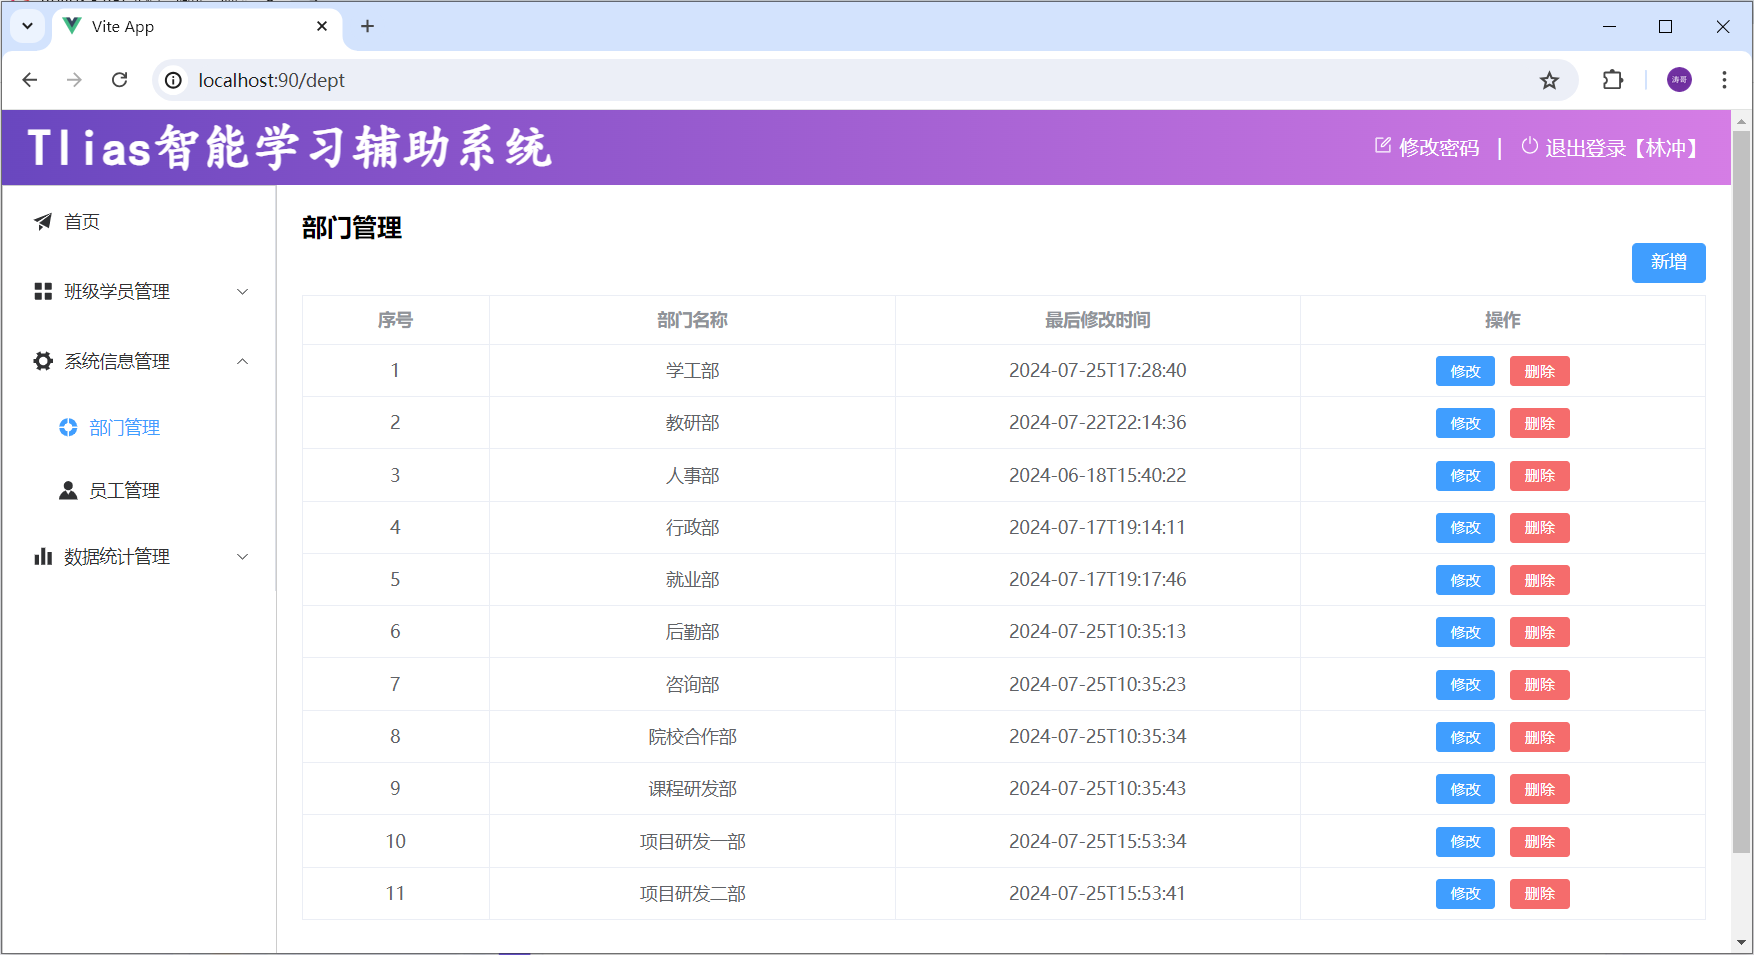


#### 3.2.2 请求访问流程

前端工程请求服务器的地址为 <code>http://localhost:90/api/depts</code>，是如何访问到后端的tomcat服务器的？

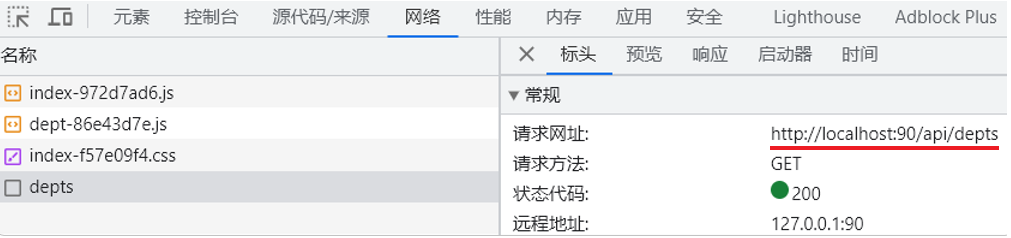

**请求链路：**浏览器访问 `localhost:90` 实际先连接 Nginx；Nginx 根据 `/api/` 规则转发到后端 `localhost:8080`。浏览器看到的是同源的 90 端口，因此通常不需要额外 CORS 配置；直接从其他端口访问后端时，才需要配置跨域策略。代理层并不会替代后端鉴权。

其实这里，是通过前端服务Nginx中提供的反向代理功能实现的。

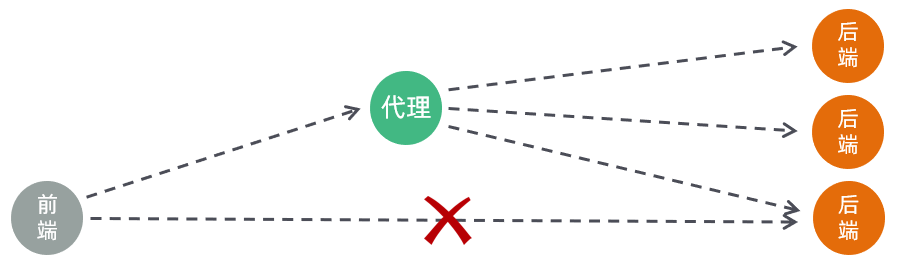

1). 浏览器发起请求，请求的是localhost:90 ，那其实请求的是nginx服务器。

2). 在nginx服务器中呢，并没有对请求直接进行处理，而是将请求转发给了后端的tomcat服务器，最终由tomcat服务器来处理该请求。

这个过程就是通过nginx的反向代理实现的。 那为什么浏览器不直接请求后端的tomcat服务器，而是直接请求nginx服务器呢，主要有以下几点原因：

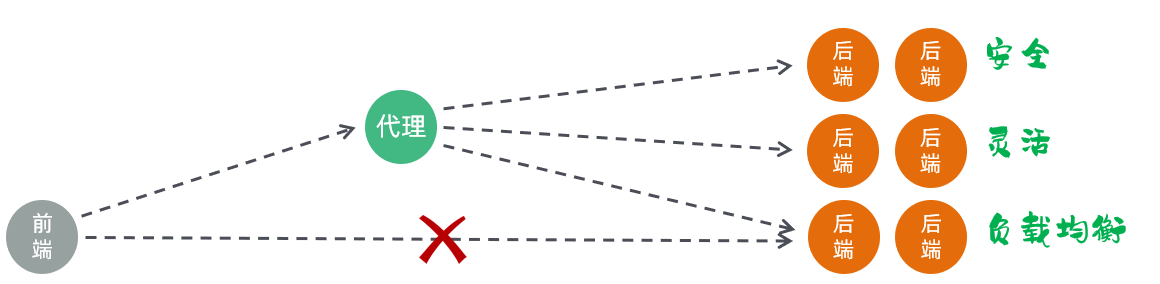

1). 安全：由于后端的tomcat服务器一般都会搭建集群，会有很多的服务器，把所有的tomcat暴露给前端，让前端直接请求tomcat，对于后端服务器是比较危险的。

2). 灵活：基于nginx的反向代理实现，更加灵活，后端想增加、减少服务器，对于前端来说是无感知的，只需要在nginx中配置即可。

3). 负载均衡：基于nginx的反向代理，可以很方便的实现后端tomcat的负载均衡操作。

具体的请求访问流程如下：

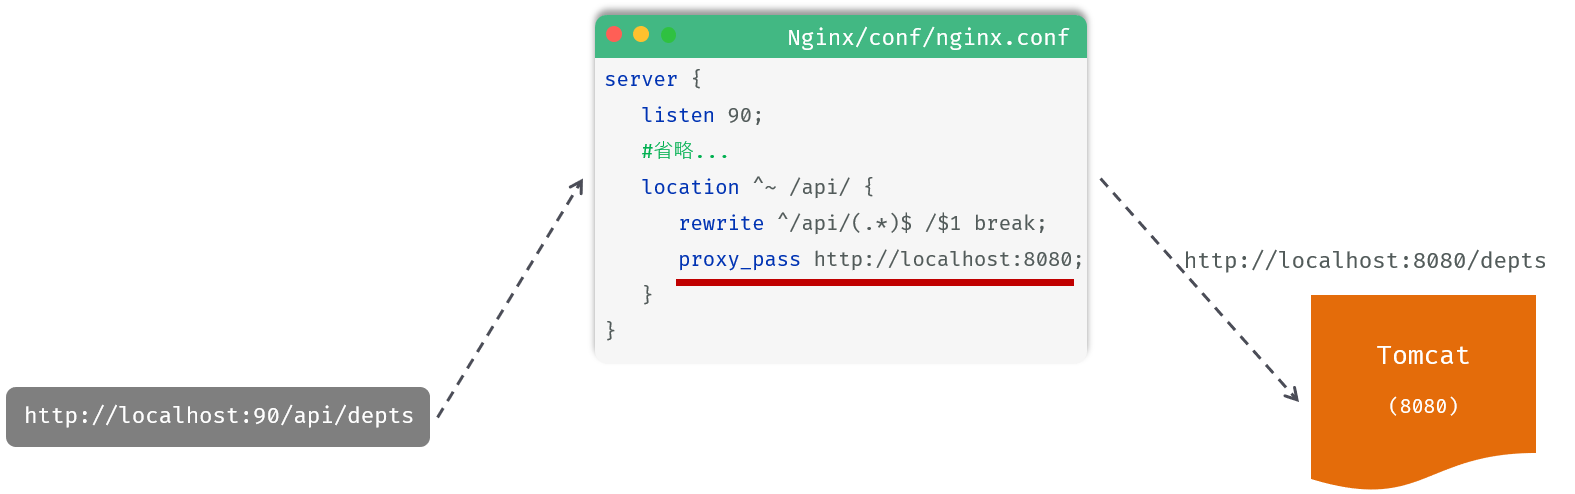

> 1. location：用于定义匹配特定uri请求的规则。
> 2. ^&#126; /api/：表示精确匹配，即只匹配以/api/开头的路径。
> 3. rewrite：该指令用于重写匹配到的uri路径。
> 4. proxy&#95;pass：该指令用于代理转发，它将匹配到的请求转发给位于后端的指令服务器。

**Nginx 指令说明与勘误：**`^~ /api/` 是“最长前缀匹配并跳过正则匹配”，不是字面意义的精确匹配；精确单一路径要用 `location = /...`。`rewrite ^/api/(.*)$ /$1 break` 会去掉 `/api` 前缀，`proxy_pass http://localhost:8080;` 再把请求转给后端；是否保留斜杠会改变最终 URI，必须用实际请求检查。修改 nginx.conf 后先执行 `nginx -t`，再 reload，避免直接重启带来中断。


## 4 删除部门


### 4.1 需求

删除部门数据。在点击 "删除" 按钮，会根据ID删除部门数据。

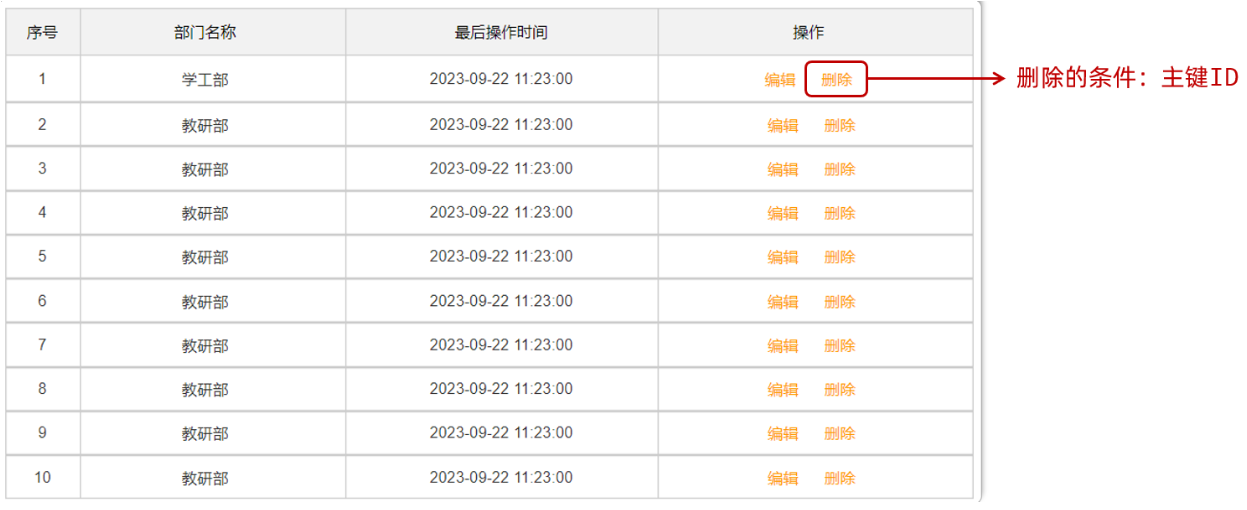

了解了需求之后，我们再看看接口文档中，关于删除部门的接口的描述，然后根据接口文档进行服务端接口的开发。


### 4.2 接口描述

参照课程资料中提供的接口文档。 <code>部门管理</code> -&gt; <code>删除部门</code>


### 4.3 思路分析

明确了删除部门的需求之后，再来梳理一下实现该功能时，三层架构每一层的职责：

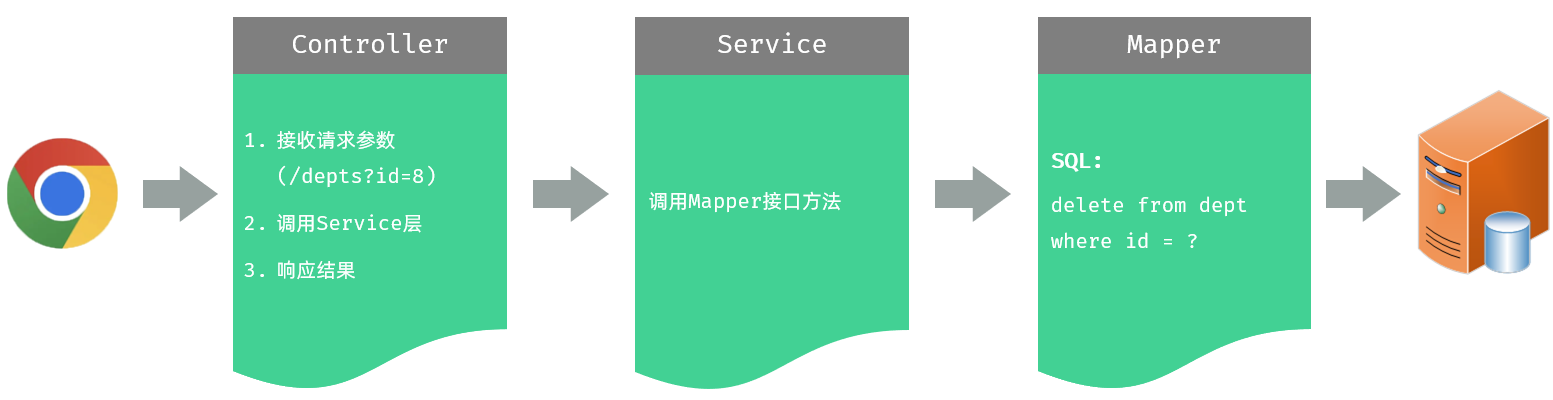


### 4.4 简单参数接收

我们看到，在controller中，需要接收前端传递的请求参数。 那接下来，我们就先来看看在服务器端的Controller程序中，如何获取这类简单参数。 具体的方案有如下三种：

- <strong>方案一：通过原始的 </strong><strong><code>HttpServletRequest</code></strong><strong> 对象获取请求参数</strong>

````java
/**
* 根据ID删除部门 - 简单参数接收: 方式一 (HttpServletRequest)
*/
@DeleteMapping("/depts")
public Result delete(HttpServletRequest request){
    String idStr = request.getParameter("id");
    int id = Integer.parseInt(idStr);
    
    System.out.println("根据ID删除部门: " + id);
    return Result.success();
}
````

**参数接收对比：**手动读取 `HttpServletRequest` 需要自己判空、类型转换和错误处理；`@RequestParam` 明确参数名，适合参数名与 Java 形参不同或需要 `required=false/defaultValue`；直接写 `Integer id` 简洁，但依赖编译参数名保留和 Spring 的参数发现。团队代码建议对公共接口显式写 `@RequestParam("id")`，可读性更稳定。

这种方案实现较为繁琐，而且还需要进行手动类型转换。<strong>【项目开发很少用】</strong>

- <strong>方案二：通过Spring提供的 </strong><strong><code>@RequestParam</code></strong><strong> </strong><strong>注解</strong><strong>，将请求参数绑定给方法形参</strong>

````java
@DeleteMapping("/depts")
public Result delete(@RequestParam("id") Integer deptId){
    System.out.println("根据ID删除部门: " + deptId);
    return Result.success();
}
````

> **补充：**`@RequestParam("id") Integer deptId` 的 `value` 必须对应 URL 的 `?id=...`。可选参数应明确 `required = false` 并处理 null，不能把缺参当成 0。参数格式错误（如 id=abc）通常由 Spring 返回 400，应通过统一异常处理返回稳定错误结构。

<code>@RequestParam</code> 注解的value属性，需要与前端传递的参数名保持一致 。

> @RequestParam注解required属性默认为true，代表该参数必须传递，如果不传递将报错。 如果参数可选，可以将属性设置为false。

- <strong>方案三：</strong><strong>如果请求参数名与形参变量名相同</strong><strong>，直接定义方法形参即可接收。（省略@RequestParam）</strong>

````java
@DeleteMapping("/depts")
public Result delete(Integer id){
    System.out.println("根据ID删除部门: " + deptId);
    return Result.success();
}
````

**勘误：**该示例方法形参叫 `id`，却打印了未定义的 `deptId`，会编译失败。应写 `System.out.println("根据ID删除部门: " + id);`。后面的完整实现已经使用了正确变量名，并调用 Service/Mapper 完成删除。

对于以上的这三种方案呢，我们<strong>推荐第三种方案</strong>。


### 4.5 代码实现

<strong>1). </strong><strong>Controller层</strong>

在 <code>DeptMapper</code>  中，增加 <code>delete</code> 方法，代码实现如下：

> **勘误：**此处应为“在 DeptController 中增加 delete 方法”；带 `@DeleteMapping`、接收 HTTP 参数和返回 Result 的方法属于 Controller。DeptMapper 只声明数据库操作。

````java
/**
 * 根据id删除部门 - delete http://localhost:8080/depts?id=1
 */
@DeleteMapping("/depts")
public Result delete(Integer id){
    System.out.println("根据id删除部门, id=" + id);
    deptService.deleteById(id);
    return Result.success();
}
````

> **补充：**删除前应校验 id 非空、记录是否存在，以及是否被员工等子表引用；是否允许级联删除由业务规则决定。Mapper 返回影响行数时可据此区分“删除成功”和“目标不存在”，不要无条件返回成功。`#{id}` 会进行参数绑定，不能用于动态表名。

<strong>2). Service层</strong>

在 <code>DeptService</code> 中，增加 <code>deleteById</code> 方法，代码实现如下：

````java
/**
 * 根据id删除部门
 */
void deleteById(Integer id);
````

在 <code>DeptServiceImpl</code> 中，增加 <code>deleteById</code> 方法，代码实现如下：

````java
public void deleteById(Integer id) {
    deptMapper.deleteById(id);
}
````

<strong>3). Mapper层</strong>

在 <code>DeptMapper</code> 中，增加 <code>deleteById</code> 方法，代码实现如下：

````java
/**
 * 根据id删除部门
 */
@Delete("delete from dept where id = #{id}")
void deleteById(Integer id);
````

如果mapper接口方法形参只有一个普通类型的参数，<code>&#35;{…}</code> 里面的属性名可以随便写，如：<code>&#35;{id}</code>、<code>&#35;{value}</code>。

对于 DML 语句来说，执行完毕，也是有返回值的，返回值代表的是增删改操作，影响的记录数，所以可以将执行 DML 语句的方法返回值设置为 Integer。 但是一般开发时，是不需要这个返回值的，所以也可以设置为void。

代码编写完毕之后，我们就可以启动服务，进行测试了。 

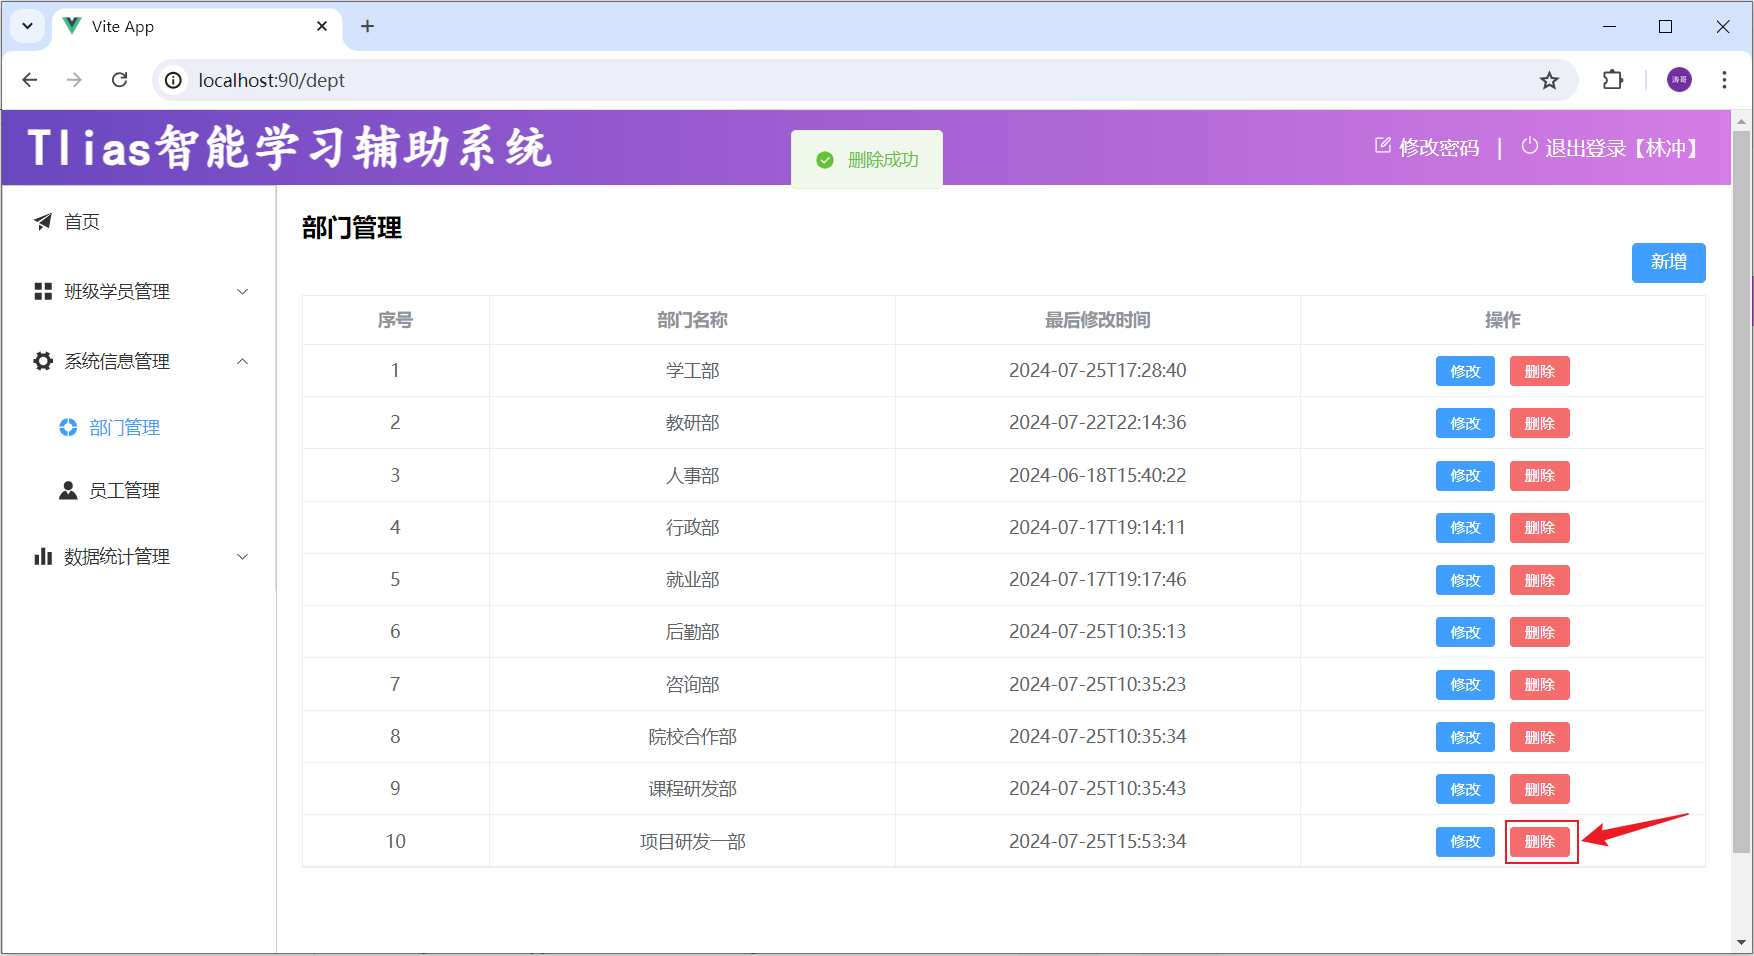


## 5 新增部门


### 5.1 需求

点击 "新增部门" 的按钮之后，弹出新增部门表单，填写部门名称之后，点击确定之后，保存部门数据。

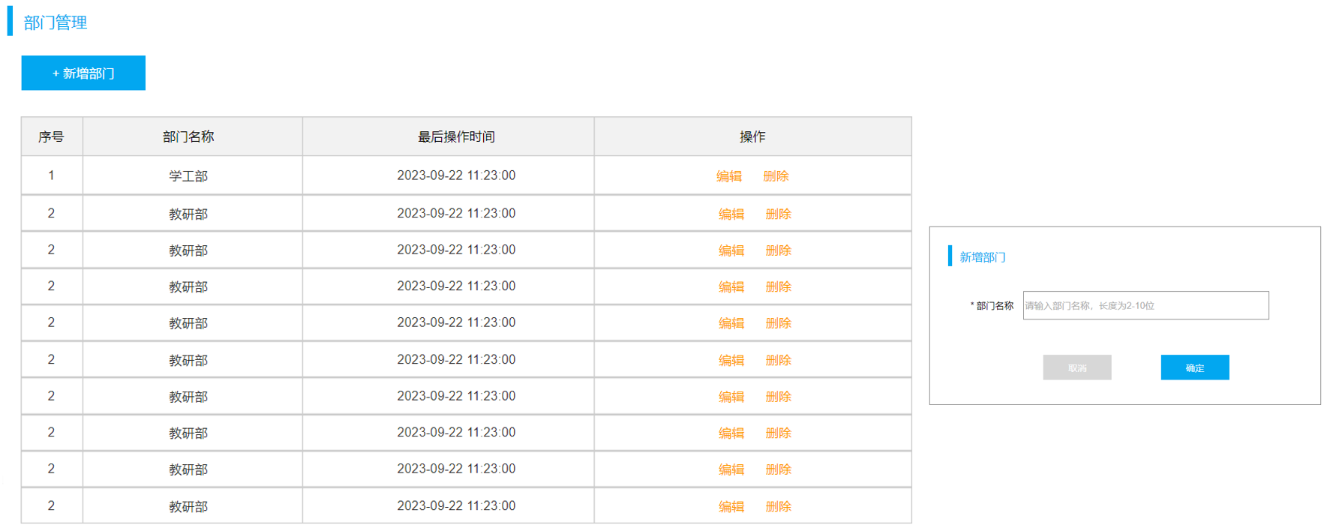

了解了需求之后，我们再看看接口文档中，关于新增部门的接口的描述，然后根据接口文档进行服务端接口的开发 。


### 5.2 接口描述

参照课程资料中提供的接口文档。 <code>部门管理</code> -&gt; <code>新增部门</code>


### 5.3 思路分析

明确了新增部门的需求之后，再来梳理一下实现该功能时，三层架构每一层的职责：

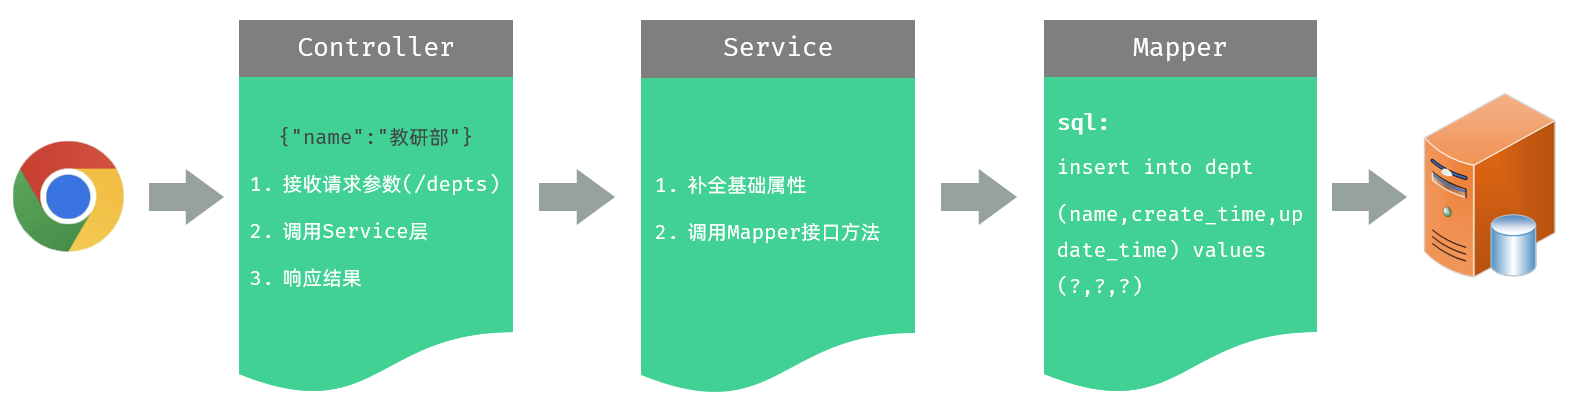


### 5.4 json参数接收

我们看到，在controller中，需要接收前端传递的请求参数。 那接下来，我们就先来看看在服务器端的Controller程序中，如何获取json格式的参数。 

- JSON格式的参数，通常会使用一个实体对象进行接收 。
- 规则：JSON数据的键名与方法形参对象的属性名相同，并需要使用<code>@RequestBody</code>注解标识。

前端传递的请求参数格式为json，内容如下：<code>{"name":"研发部"}</code>。这里，我们可以通过一个对象来接收，只需要保证对象中有name属性即可。

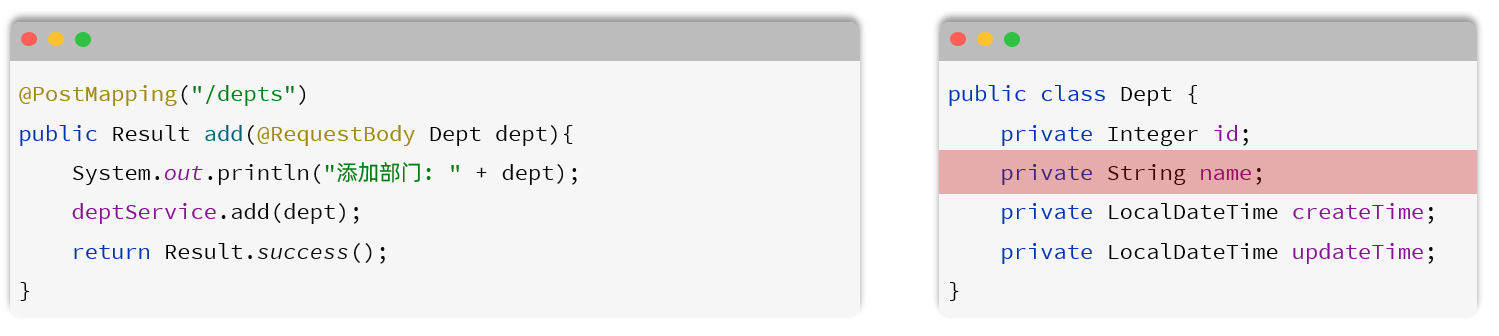


### 5.5 代码实现

<strong>1). Controller层</strong>

在<code>DeptController</code>中增加方法save，具体代码如下：

````java
/**
 * 新增部门 - POST http://localhost:8080/depts   请求参数：{"name":"研发部"}
 */
@PostMapping("/depts")
public Result save(@RequestBody Dept dept){
    System.out.println("新增部门, dept=" + dept);
    deptService.save(dept);
    return Result.success();
}
````

> **请求体说明：**`@RequestBody` 读取 JSON 请求体，客户端要发送 `Content-Type: application/json`，字段名 `name` 要与 Java 属性一致。缺少请求体、JSON 语法错误或类型不匹配时通常是 400；不要在 Controller 中把原始 JSON 当查询字符串解析。

<strong>2). Service层</strong>

在<code>DeptService</code>中增加接口方法save，具体代码如下：

````java
/**
 * 新增部门
 */
void save(Dept dept);
````

在<code>DeptServiceImpl</code>中增加save方法，完成添加部门的操作，具体代码如下：

````java
public void save(Dept dept) {
    //补全基础属性
    dept.setCreateTime(LocalDateTime.now());
    dept.setUpdateTime(LocalDateTime.now());
    //保存部门
    deptMapper.insert(dept);
}
````

**时间字段补充：**创建和更新时间应由服务端生成，不能信任前端传来的时间。一次保存中两个字段可以使用同一个 `now` 值，避免极短时间差；更大型项目可在数据库默认值、审计拦截器或领域服务中统一维护。新增前还应校验名称非空和唯一约束冲突。

<strong>3). Mapper层</strong>

````java
/**
 * 保存部门
 */
@Insert("insert into dept(name,create_time,update_time) values(#{name},#{createTime},#{updateTime})")
void insert(Dept dept);
````

> **补充：**`#{createTime}` 取的是 `Dept.createTime` 属性，不是数据库列名 `create_time`。插入方法可返回 `int` 检查影响行数，主键自增回填则需配置 `useGeneratedKeys` / `keyProperty`。唯一键冲突应转换成可理解的业务错误，而不是直接把 SQL 异常返回前端。

如果在mapper接口中，需要传递多个参数，可以把多个参数封装到一个对象中。 在SQL语句中获取参数的时候，<code>&#35;{...}</code> 里面写的是对象的属性名【注意是属性名，不是表的字段名】。

代码编写完毕之后，我们就可以启动服务，进行测试了。 

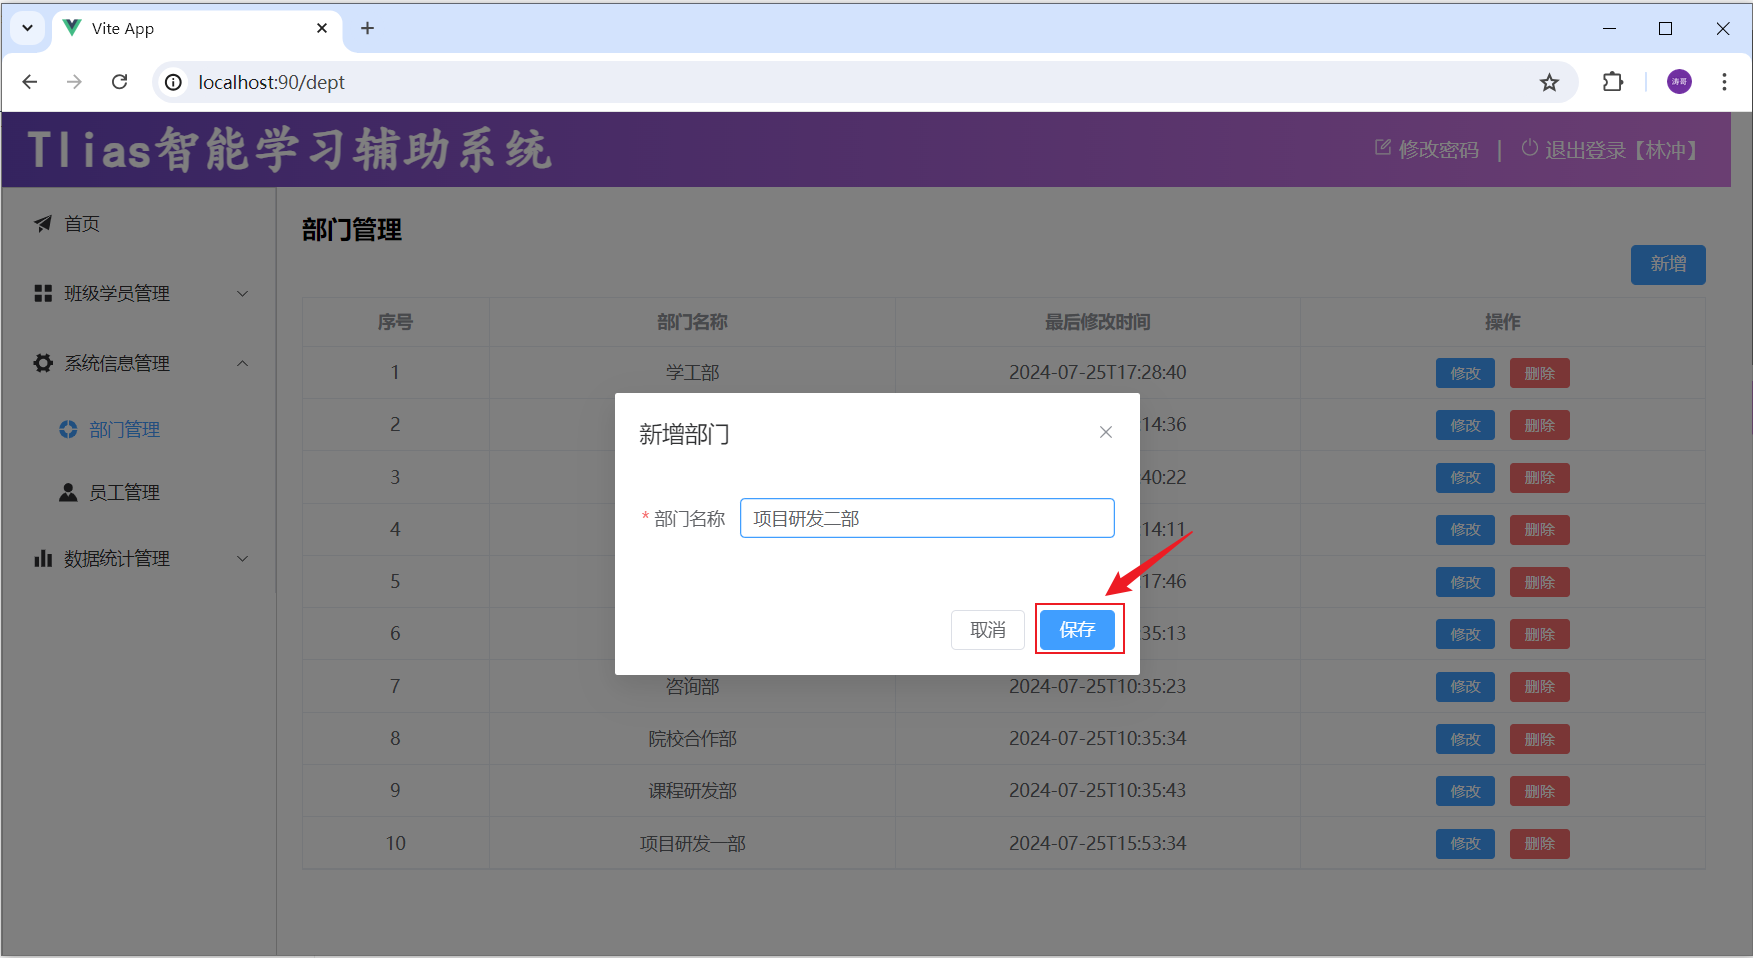

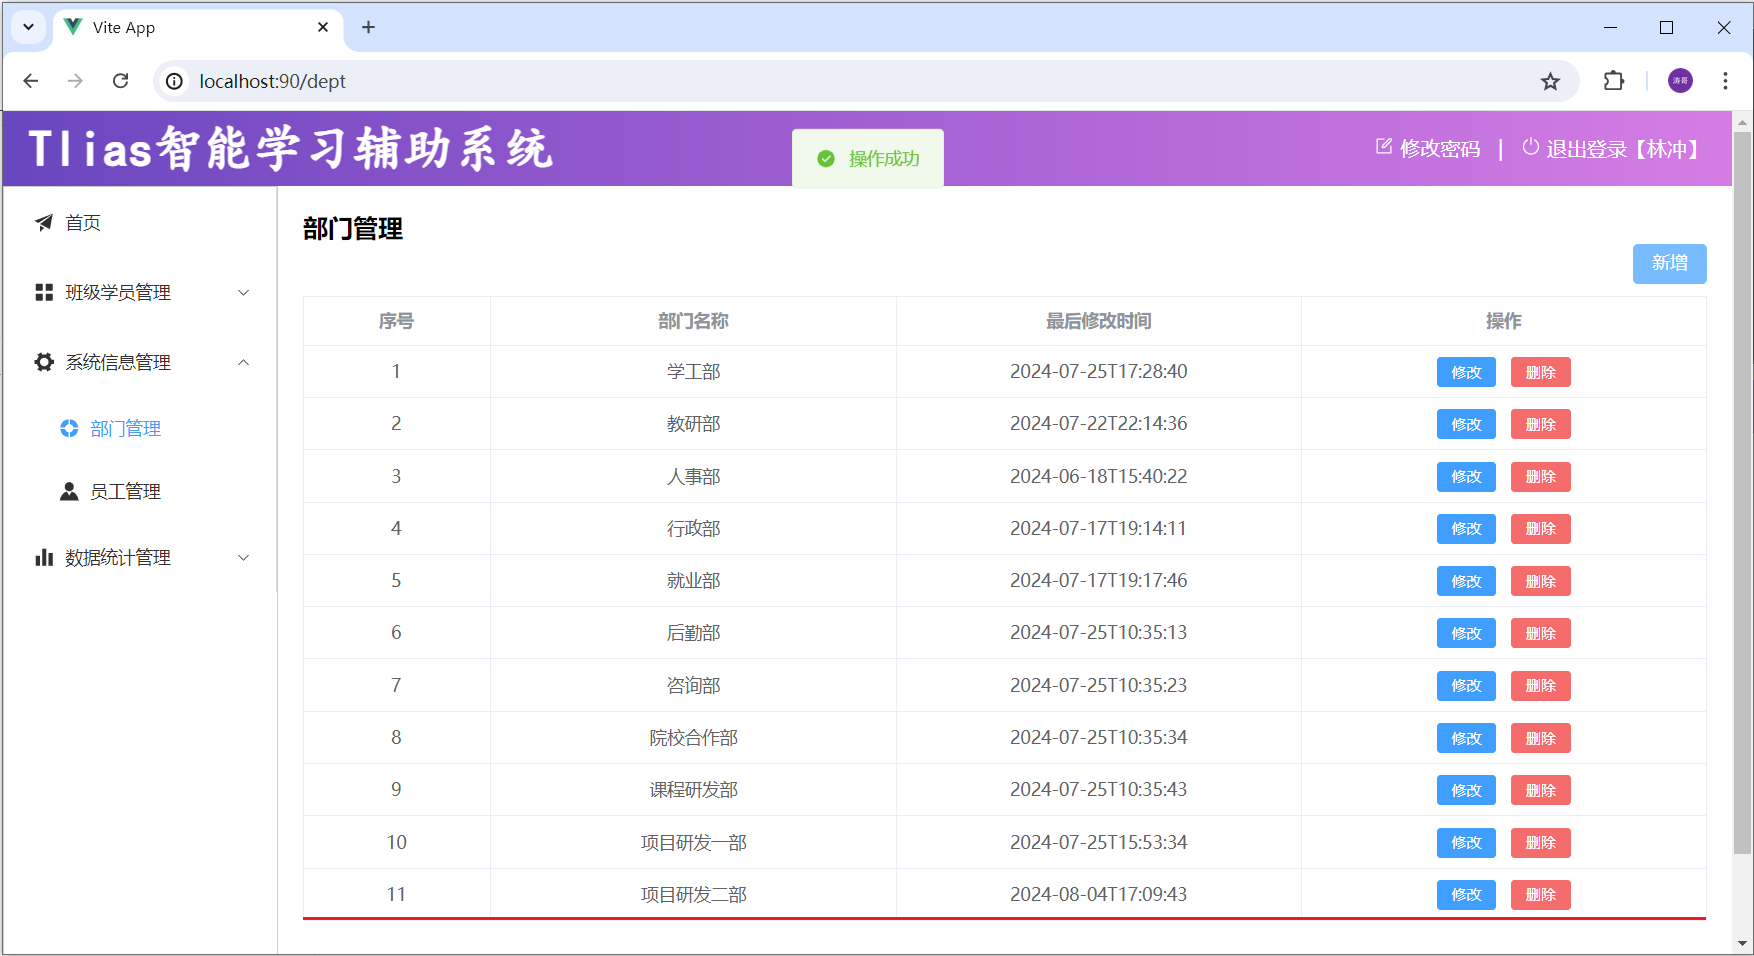


## 6 修改部门

对于任何业务的修改功能来说，一般都会分为两步进行：查询回显、修改数据。

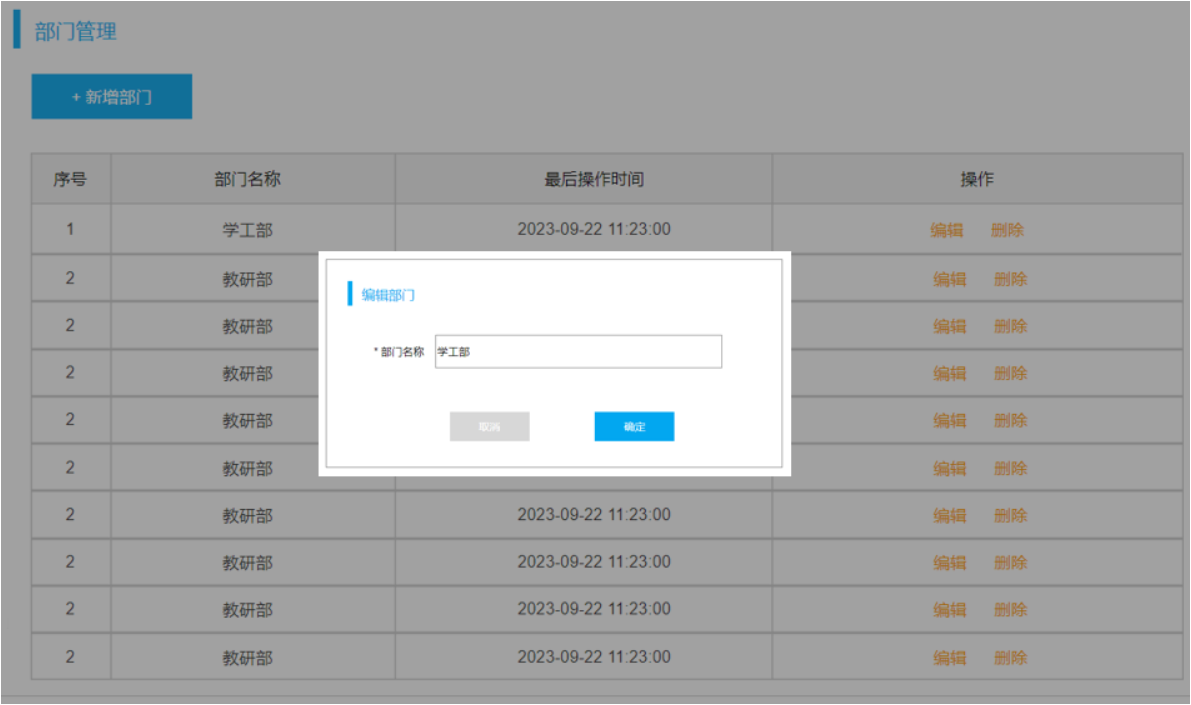


### 6.1 查询回显


#### 6.1.1 需求

当我们点击 "编辑" 的时候，需要根据ID查询部门数据，然后用于页面回显展示。

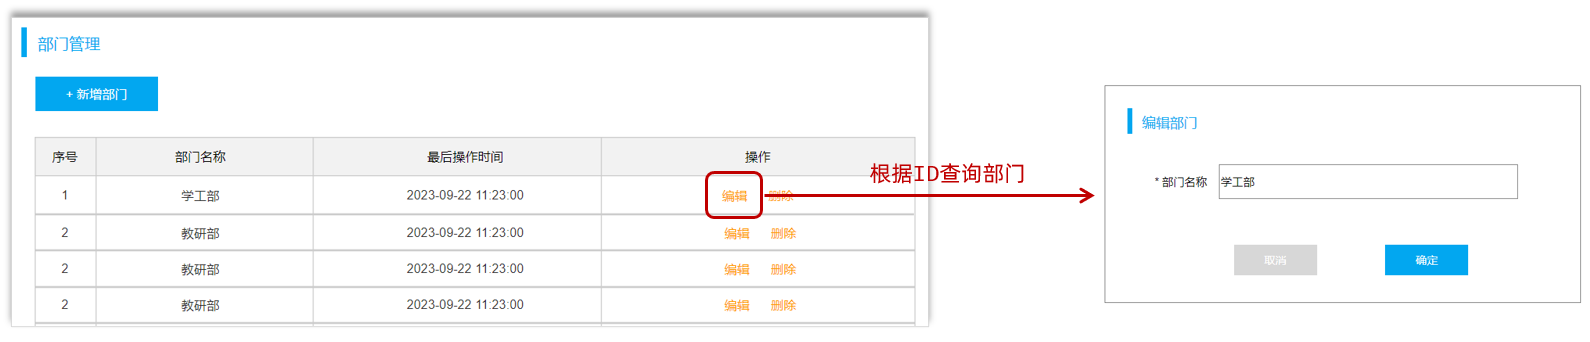


#### 6.1.2 接口描述

参照参照课程资料中提供的接口文档。 <code>部门管理</code> -&gt; <code>根据ID查询</code>


#### 6.1.3 思路分析

明确了根据ID查询部门的需求之后，再来梳理一下实现该功能时，三层架构每一层的职责：

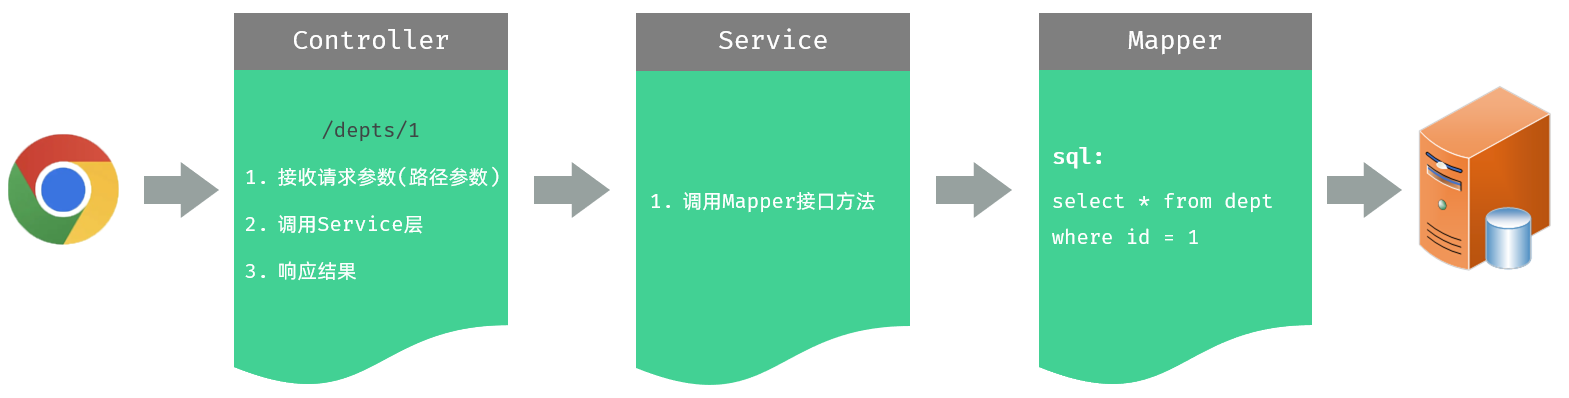

了解了需求之后，我们再看看接口文档中，关于根据ID查询部门的接口的描述，然后根据接口文档进行服务端接口的开发 。


#### 6.1.4 路径参数接收

<code>/depts/1</code>，<code>/depts/2</code> 这种在url中传递的参数，我们称之为<strong>路径参数</strong>。 那么如何接收这样的路径参数呢 ？

路径参数：通过请求URL直接传递参数，使用{…}来标识该路径参数，需要使用 <strong><code>@PathVariable</code></strong>获取路径参数。如下所示：

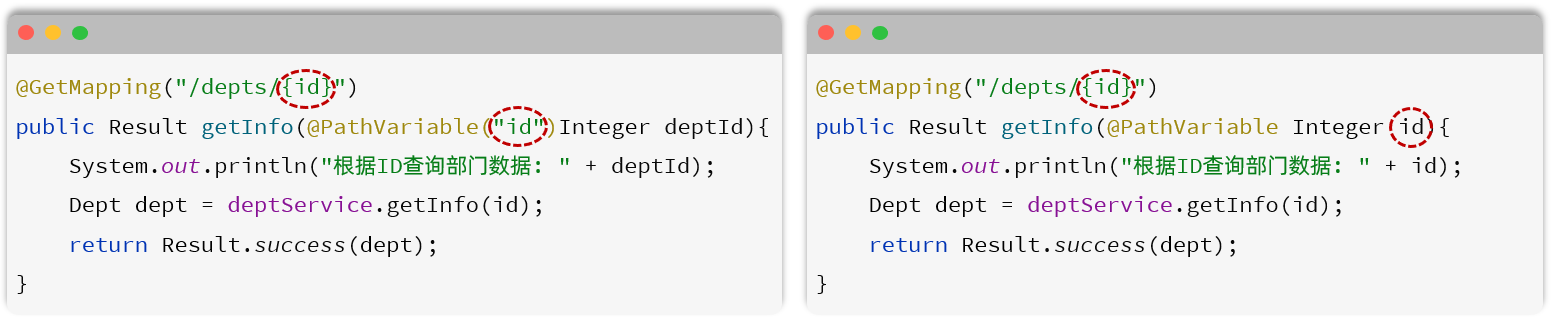

如果路径参数名与controller方法形参名称一致，<code>@PathVariable</code>注解的value属性是可以省略的。


#### 6.1.5 代码实现

<strong>1). Controller层</strong>

在 <code>DeptController</code> 中增加 <code>getById</code>方法，具体代码如下：

````java
/**
 * 根据ID查询 - GET http://localhost:8080/depts/1
 */
@GetMapping("/depts/{id}")
public Result getById(@PathVariable Integer id){
    System.out.println("根据ID查询, id=" + id);
    Dept dept = deptService.getById(id);
    return Result.success(dept);
}
````

> **补充：**`@PathVariable` 绑定的是路径 `/depts/{id}`，不是查询字符串 `?id=1`。路径变量名不一致时写 `@PathVariable("id") Integer deptId`；使用 `@PathVariable Integer id` 省略 value 时，建议确保编译保留参数名，或显式写 value 避免环境差异。

<strong>2). Service层</strong>

在 <code>DeptService</code> 中增加 <code>getById</code>方法，具体代码如下：

````java
/**
 * 根据id查询部门
 */
Dept getById(Integer id);
````

在 <code>DeptServiceImpl</code> 中增加 <code>getById</code>方法，具体代码如下：

````java
public Dept getById(Integer id) {
    return deptMapper.getById(id);
}
````

<strong>3). Mapper层</strong>

在 <code>DeptMapper</code> 中增加 <code>getById</code> 方法，具体代码如下：

````java
/**
* 根据ID查询部门数据
*/
@Select("select id, name, create_time, update_time from dept where id = #{id}")
Dept getById(Integer id);
````

> **补充：**按 id 查询可能返回 null，Controller 应明确 404 还是统一业务错误。SQL 列出字段能避免把 password 或未来新增敏感列意外返回；本例只返回部门的四个字段。

代码编写完毕之后，我们就可以启动服务，进行测试了。 

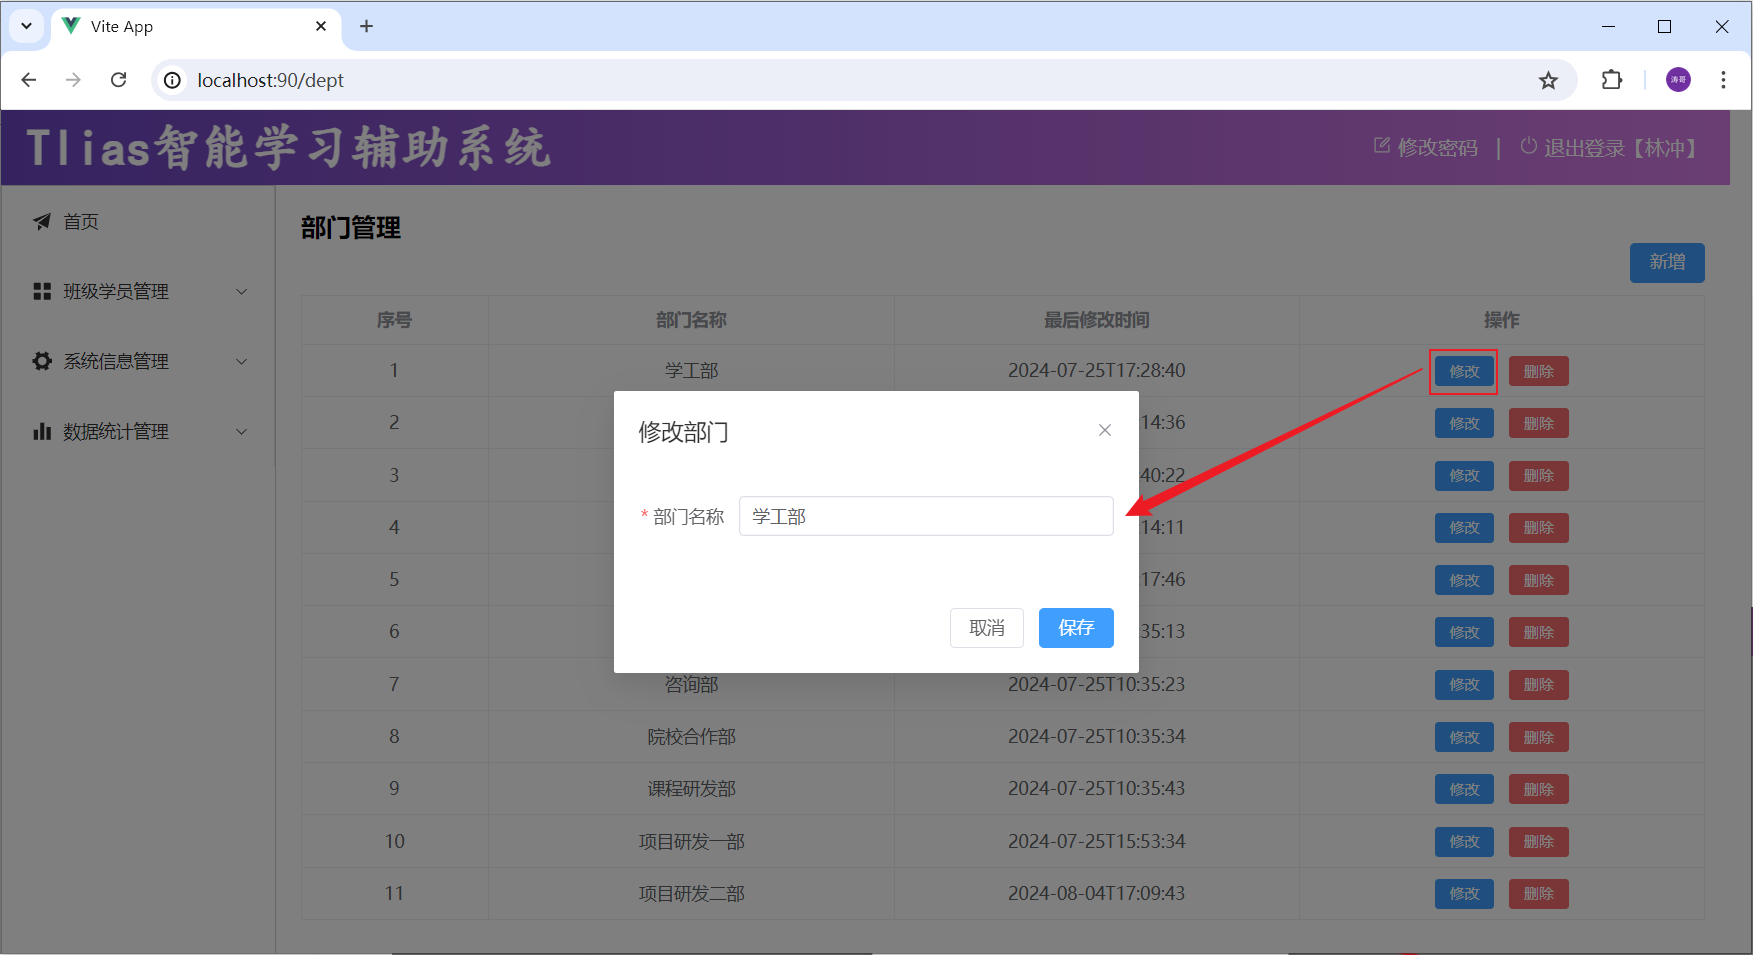


### 6.2 修改数据


#### 6.2.1 需求

查询回显回来之后，就可以对部门的信息进行修改了，修改完毕之后，点击确定，此时，就需要根据ID修改部门的数据。

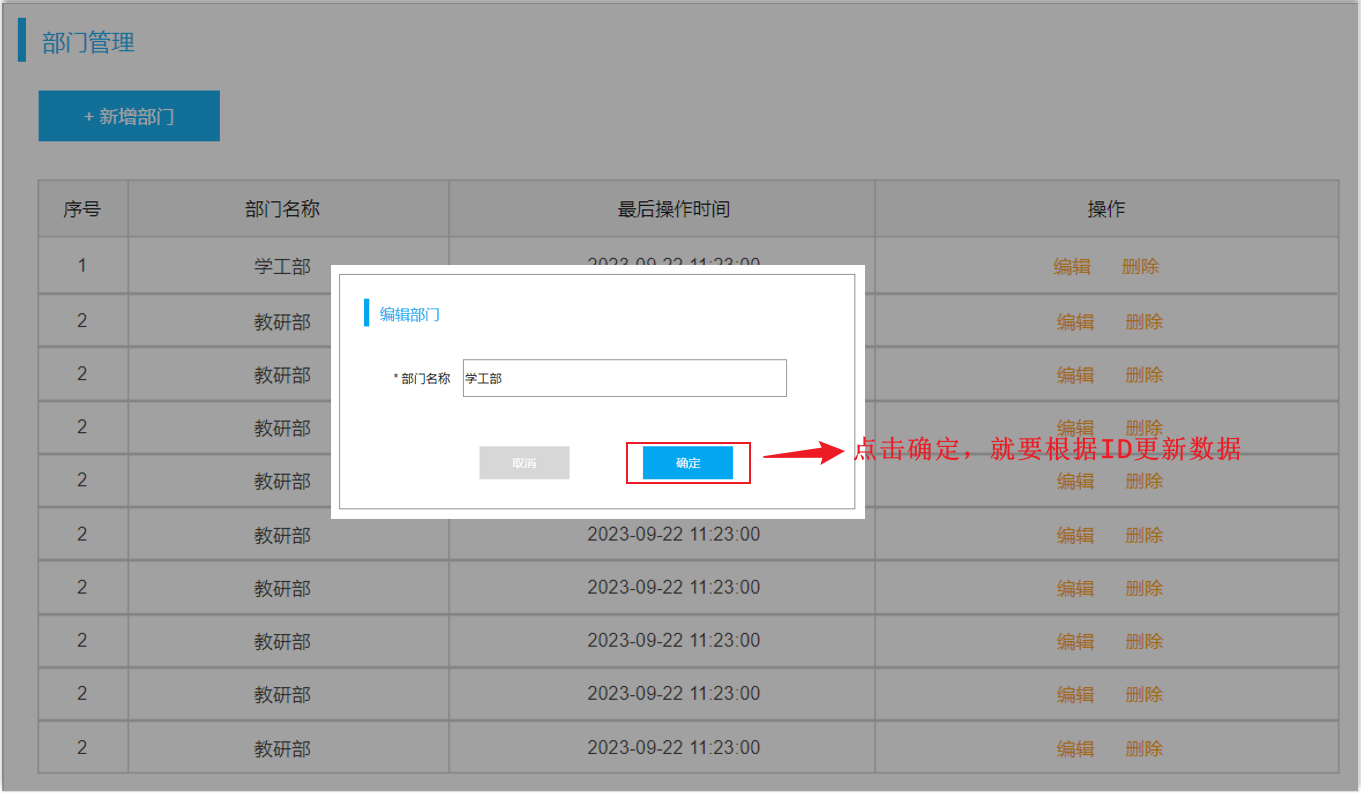

了解了需求之后，我们再看看接口文档中，关于修改部门的接口的描述，然后根据接口文档进行服务端接口的开发 。


#### 6.2.2 接口描述

参照参照课程资料中提供的接口文档。 <code>部门管理</code> -&gt; <code>修改部门</code>


#### 6.2.3 思路分析

参照接口文档，梳理三层架构每一层的职责：

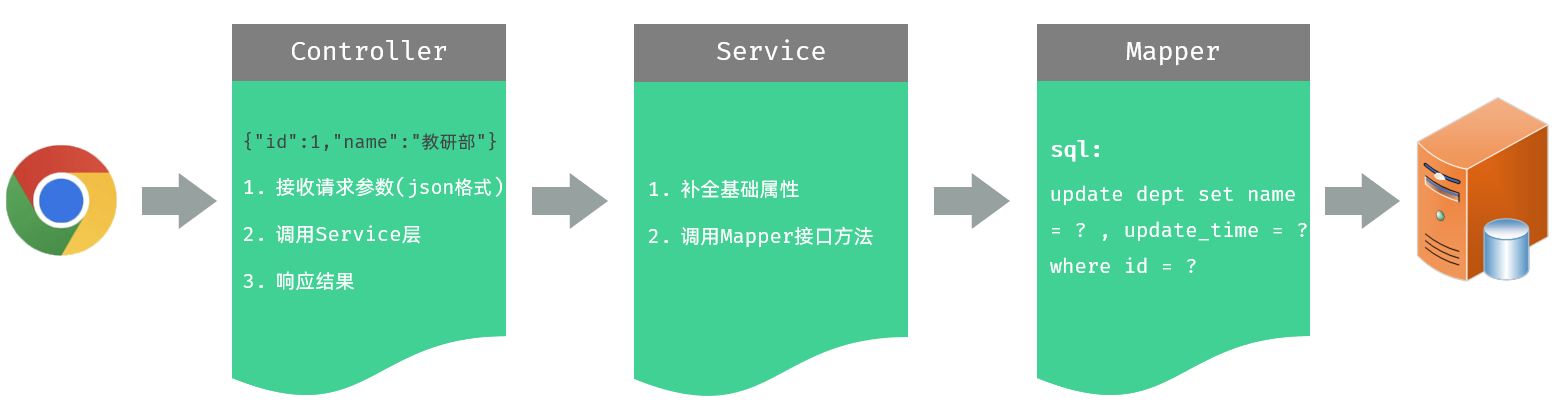

通过接口文档，我们可以看到前端传递的请求参数是json格式的请求参数，在Controller的方法中，我们可以通过 <code>@RequestBody</code> 注解来接收，并将其封装到一个对象中。


#### 6.2.4 代码实现

<strong>1). Controller层</strong>

在 <code>DeptController</code> 中增加 <code>update</code> 方法，具体代码如下：

````java
/**
 * 修改部门 - PUT http://localhost:8080/depts  请求参数：{"id":1,"name":"研发部"}
 */
@PutMapping("/depts")
public Result update(@RequestBody Dept dept){
    System.out.println("修改部门, dept=" + dept);
    deptService.update(dept);
    return Result.success();
}
````

> **补充：**更新请求只接收允许修改的字段，id 必须来自路径或可信请求体并做存在性校验。不要让前端覆盖 `createTime`；更新 `updateTime` 由服务端生成。名称唯一时，重名会触发数据库唯一约束，应转成 409 或团队约定的业务错误。

<strong>2). Service层</strong>

在 <code>DeptService</code> 中增加 <code>update</code> 方法。

````java
/**
 * 修改部门
 */
void update(Dept dept);
````

在 <code>DeptServiceImpl</code> 中增加 <code>update</code> 方法。 由于是修改操作，每一次修改数据，都需要更新updateTime。所以，具体代码如下：

````java
public void update(Dept dept) {
    //补全基础属性
    dept.setUpdateTime(LocalDateTime.now());
    //保存部门
    deptMapper.update(dept);
}
````

> **补充：**Service 是事务边界和业务规则的合适位置。单条更新通常可直接执行；若更新部门同时要处理其他表，应在 Service 方法上使用 `@Transactional`，让相关操作一起提交或回滚。

<strong>3). Mapper层</strong>

在 <code>DeptMapper</code> 中增加 <code>update</code> 方法，具体代码如下：

````java
/**
 * 更新部门
 */
@Update("update dept set name = #{name},update_time = #{updateTime} where id = #{id}")
void update(Dept dept);
````

> **勘误与安全：**SQL 中列名 `update_time` 与对象属性 `updateTime` 的对应依赖参数对象属性读取，不依赖数据库列名。建议返回 `int` 以判断影响行数；更新语句只设置允许修改的列，避免把 null 覆盖到未提交字段。

代码编写完毕之后，我们就可以启动服务，进行测试了。 

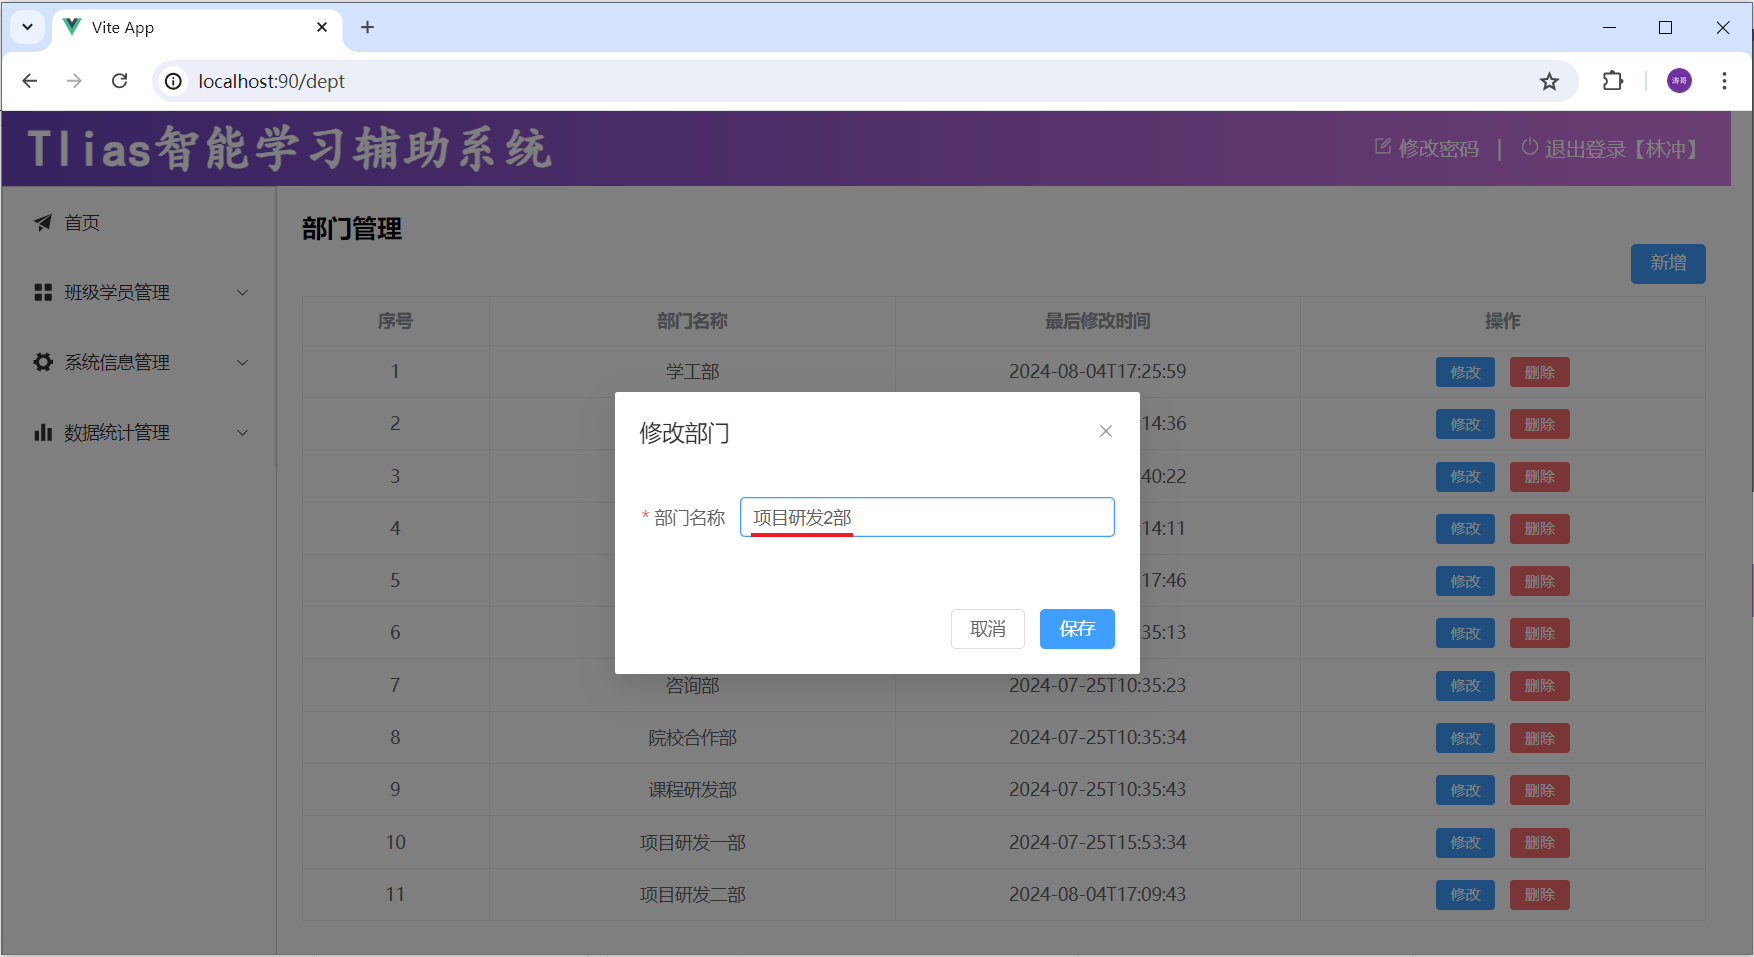

修改完成之后，我们可以看到最新的数据，如下：

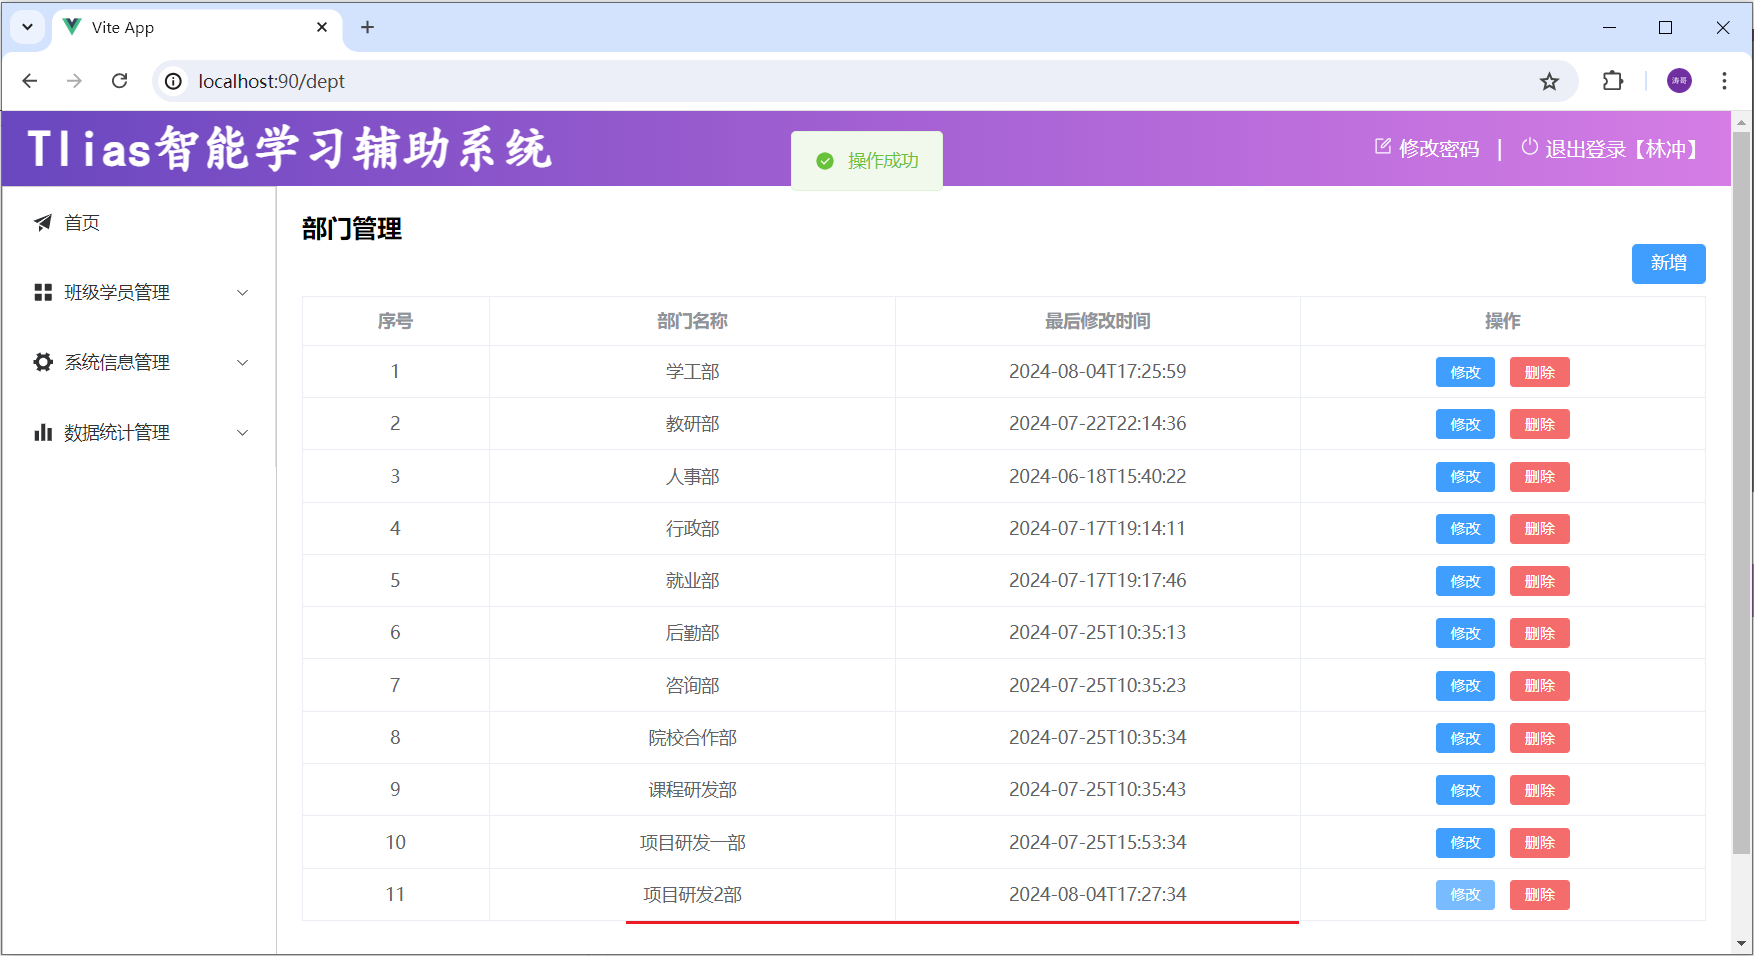


#### 6.2.5 @RequestMapping

到此呢，关于基本的部门的增删改查功能，我们已经实现了。  我们会发现，我们在 <code>DeptController</code> 中所定义的方法，所有的请求路径，都是 <code>/depts</code> 开头的，只要操作的是部门数据，请求路径都是 <code>/depts</code> 开头。 

那么这个时候，我们其实是可以把这个公共的路径 <code>/depts</code> 抽取到类上的，那在各个方法上，就可以省略了这个 <code>/depts</code> 路径。 代码如下：

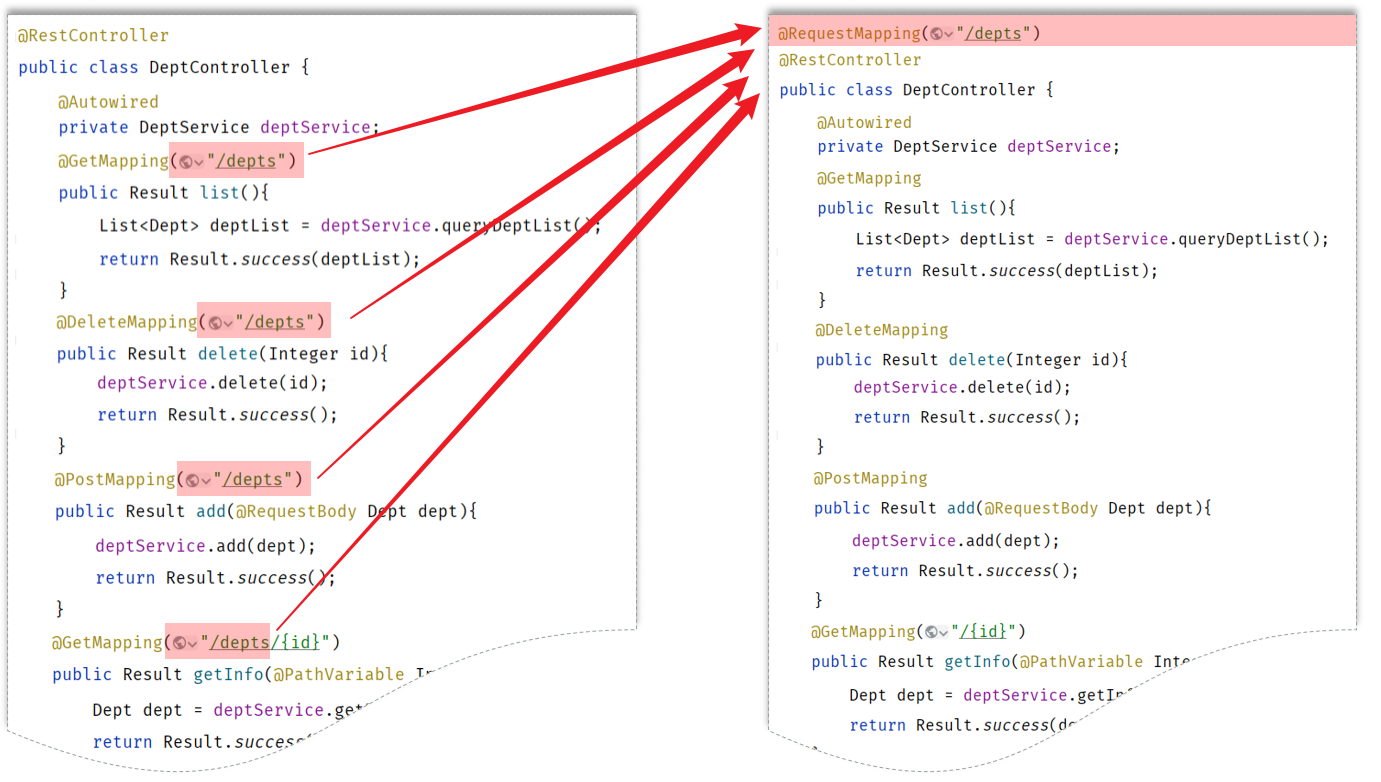

> **路径说明：**类级别 `@RequestMapping("/depts")` 与方法级路径拼接。推荐最终形式：`@RequestMapping("/depts")` + `@GetMapping`、`@PostMapping`、`@PutMapping`、`@DeleteMapping`；不要在方法上重复 `/depts`。类级别也可加 `@RequestMapping("/api/depts")`，但要与 Nginx 是否剥离 `/api` 前缀保持一致。

> 一个完整的请求路径，应该是类上的 @RequestMapping 的value属性 + 方法上的 @RequestMapping的value属性。


## 7 日志技术


### 7.1 概述

- 什么是日志？

    - 日志就好比生活中的日记，可以随时随地记录你生活中的点点滴滴。
    - 程序中的日志，是用来记录应用程序的运行信息、状态信息、错误信息的。 

- 为什么要在程序中记录日志呢？

    - 便于追踪应用程序中的数据信息、程序的执行过程。
    - 便于对应用程序的性能进行优化。
    - 便于应用程序出现问题之后，排查问题，解决问题。
    - 便于监控系统的运行状态。
    - ... ...

- 之前我们编写程序时，也可以通过 <code>System.out.println(...) </code>来输出日志，为什么我们还要学习单独的日志技术呢？

    这是因为，如果通过  <code>System.out.println(...) </code> 来记录日志，会存在以下几点问题：

- 硬编码。所有的记录日志的代码，都是硬编码，没有办法做到灵活控制，要想不输出这个日志了，只能删除掉记录日志的代码。
- 只能输出日志到控制台。
- 不便于程序的扩展、维护。

所以，在现在的项目开发中，我们一般都会使用专业的日志框架，来解决这些问题。


### 7.2 日志框架

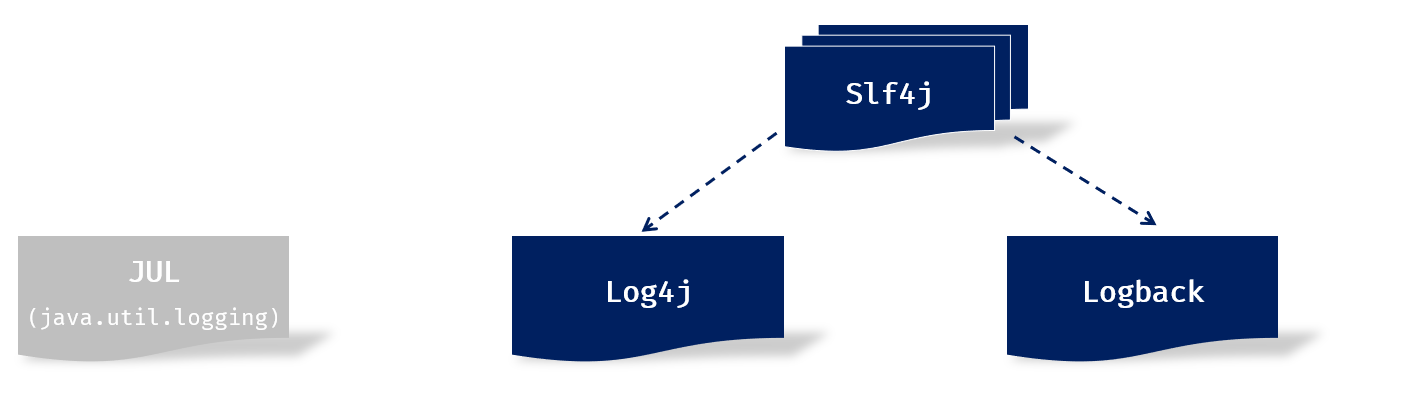

**框架关系：**SLF4J 是日志门面，应用代码依赖 `org.slf4j.Logger` 接口；Logback 是常用实现。Spring Boot 默认已通过 starter 带入 Logback，不需要为了使用 `@Slf4j` 再重复添加同版本依赖。若替换实现，要避免多个绑定同时存在。

- <strong>JUL</strong><strong>：</strong>这是JavaSE平台提供的官方日志框架，也被称为JUL。配置相对简单，但不够灵活，性能较差。
- <strong>Log4j</strong><strong>：</strong>一个流行的日志框架，提供了灵活的配置选项，支持多种输出目标。
- <strong>Logback：</strong>基于Log4j升级而来，提供了更多的功能和配置选项，性能由于Log4j。
- <strong>Slf4j</strong><strong>：</strong>（Simple Logging Facade for Java）简单日志门面，提供了一套日志操作的标准接口及抽象类，允许应用程序使用不同的底层日志框架。


### 7.3 Logback入门

<strong>1). 准备工作：</strong><strong>引入logback的依赖</strong><strong>（</strong><strong>springboot中无需引入</strong><strong>，</strong><strong>在springboot中已经传递了此依赖</strong><strong>）</strong>

````xml
<dependency>
    <groupId>ch.qos.logback</groupId>
    <artifactId>logback-classic</artifactId>
    <version>1.4.11</version>
</dependency>
````

> **版本说明：**独立 Java 项目可以显式引入 Logback；Spring Boot 项目优先使用 `spring-boot-starter-logging` 传递的版本。手动固定 `1.4.11` 可能与当前 Boot 管理版本不一致，除非有明确兼容性要求。

<strong>2). 引入配置文件 </strong><strong><code>logback.xml</code></strong><strong>  （资料中已经提供，拷贝进来，放在 </strong><strong><code>src/main/resources</code></strong><strong> 目录下； 或者直接AI生成）</strong>

````xml
<?xml version="1.0" encoding="UTF-8"?>
<configuration>
    <!-- 控制台输出 -->
    <appender name="STDOUT" class="ch.qos.logback.core.ConsoleAppender">
        <encoder class="ch.qos.logback.classic.encoder.PatternLayoutEncoder">
            <!--格式化输出：%d表示日期，%thread表示线程名，%-5level：级别从左显示5个字符宽度  %msg：日志消息，%n是换行符 -->
            <pattern>%d{yyyy-MM-dd HH:mm:ss.SSS} [%thread] %-5level %logger{50}-%msg%n</pattern>
        </encoder>
    </appender>

    <!-- 日志输出级别 -->
    <root level="ALL">
        <appender-ref ref="STDOUT" />
    </root>
</configuration>
````

**配置补充：**`root level="ALL"` 会输出大量 DEBUG/TRACE 日志，只适合学习。生产通常按包名设置级别，并把应用日志与框架日志分开控制。文件路径不要写死为某台 Windows 机器的 `D:/`；使用 `${LOG_HOME:-./logs}` 等可配置目录，并确认进程有写权限。

<strong>3). 记录日志：定义日志记录对象Logger，记录日志</strong>

````java
public class LogTest {
    
    //定义日志记录对象
    private static final Logger log = LoggerFactory.getLogger(LogTest.class);

    @Test
    public void testLog(){
        log.debug("开始计算...");
        int sum = 0;
        int[] nums = {1, 5, 3, 2, 1, 4, 5, 4, 6, 7, 4, 34, 2, 23};
        for (int i = 0; i < nums.length; i++) {
            sum += nums[i];
        }
        log.info("计算结果为: "+sum);
        log.debug("结束计算...");
    }

}
````

运行单元测试，可以在控制台中看到输出的日志，如下所示：

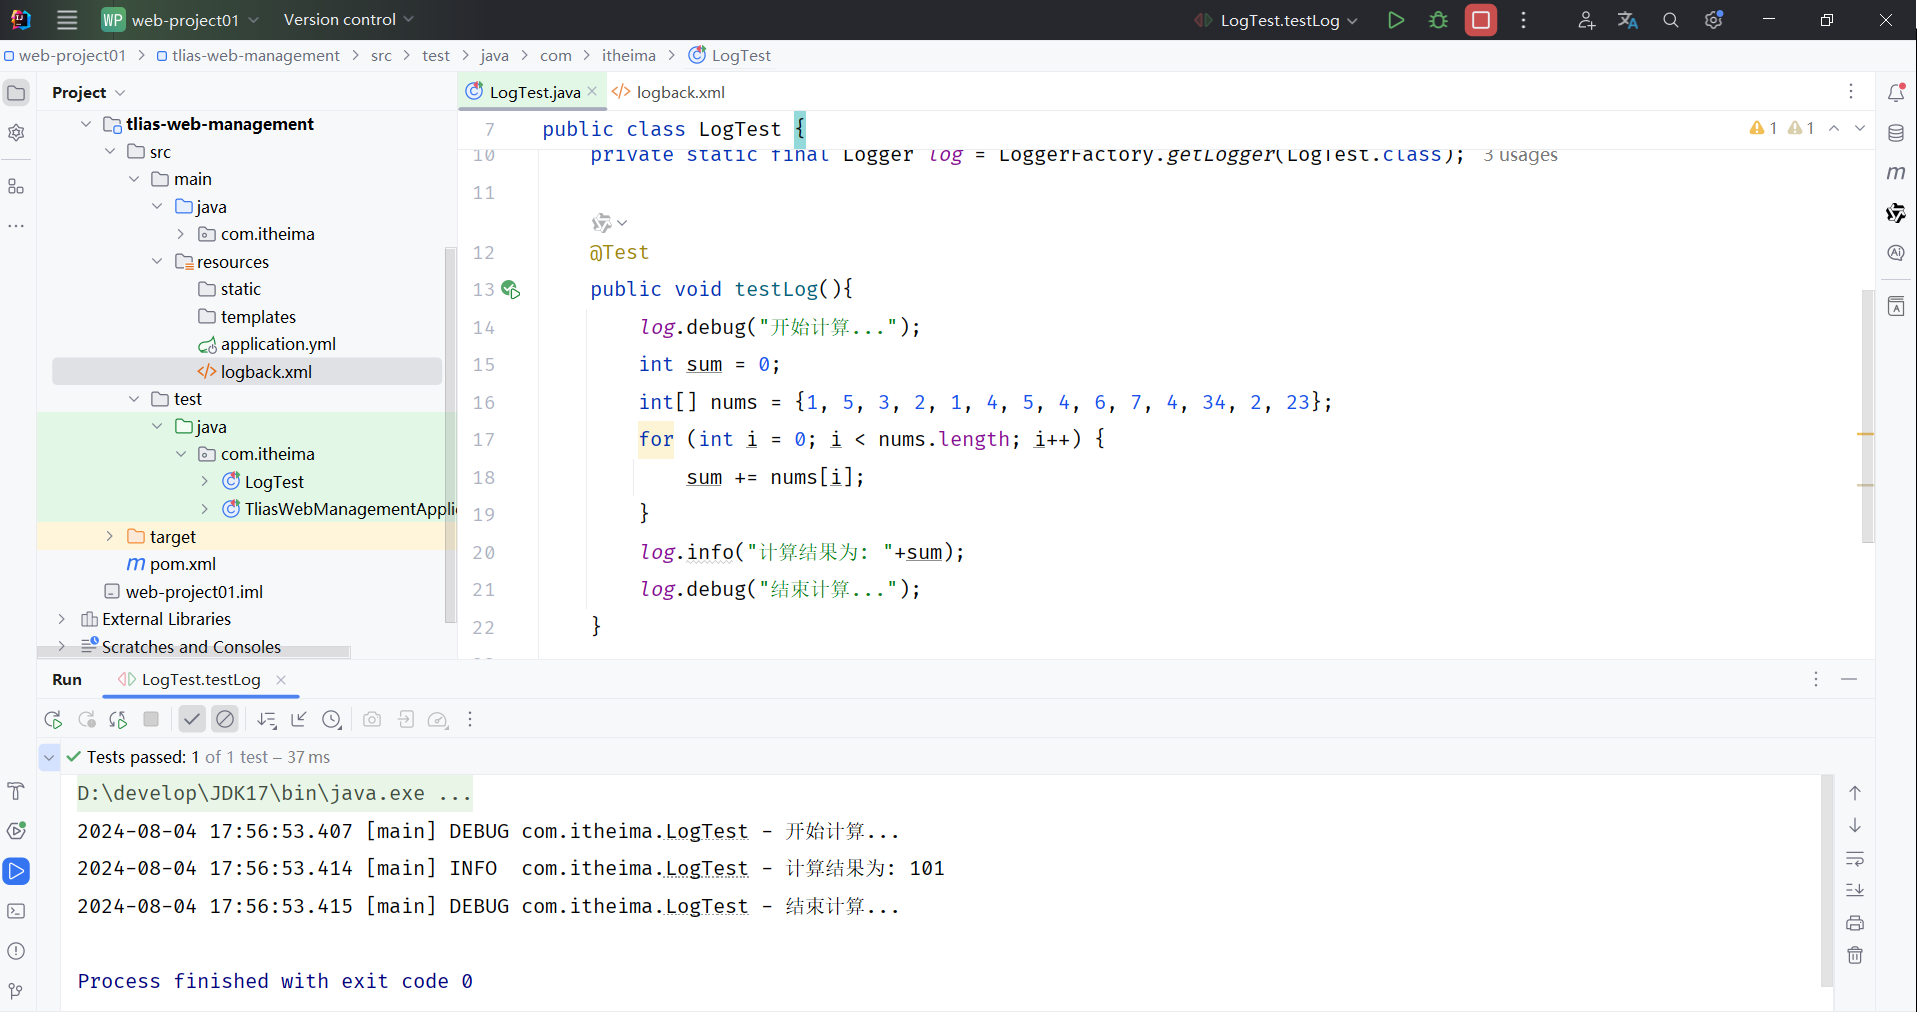

我们可以看到在输出的日志信息中，不仅输出了日志的信息，还包括：日志的输出时间、线程名、具体在那个类中输出的。


### 7.4 Logback配置文件

Logback日志框架的配置文件叫 <code>logback.xml</code> 。 

该配置文件是对Logback日志框架输出的日志进行控制的，可以来配置输出的格式、位置及日志开关等。

常用的两种输出日志的位置：控制台、系统文件。

<strong>1). 如果需要输出日志到控制台。添加如下配置：</strong>

````xml
<!-- 控制台输出 -->
<appender name="STDOUT" class="ch.qos.logback.core.ConsoleAppender">
    <encoder class="ch.qos.logback.classic.encoder.PatternLayoutEncoder">
            <!--格式化输出：%d 表示日期，%thread 表示线程名，%-5level表示级别从左显示5个字符宽度，%msg表示日志消息，%n表示换行符 -->
            <pattern>%d{yyyy-MM-dd HH:mm:ss.SSS} [%thread] %-5level %logger{50}-%msg%n</pattern>
    </encoder>
</appender>
````

<strong>2). 如果需要输出日志到文件。添加如下配置：</strong>

````xml
<!-- 按照每天生成日志文件 -->
<appender name="FILE" class="ch.qos.logback.core.rolling.RollingFileAppender">
    <rollingPolicy class="ch.qos.logback.core.rolling.SizeAndTimeBasedRollingPolicy">
        <!-- 日志文件输出的文件名, %i表示序号 -->
        <FileNamePattern>D:/tlias-%d{yyyy-MM-dd}-%i.log</FileNamePattern>
        <!-- 最多保留的历史日志文件数量 -->
        <MaxHistory>30</MaxHistory>
        <!-- 最大文件大小，超过这个大小会触发滚动到新文件，默认为 10MB -->
        <maxFileSize>10MB</maxFileSize>
    </rollingPolicy>

    <encoder class="ch.qos.logback.classic.encoder.PatternLayoutEncoder">
        <!--格式化输出：%d 表示日期，%thread 表示线程名，%-5level表示级别从左显示5个字符宽度，%msg表示日志消息，%n表示换行符 -->
        <pattern>%d{yyyy-MM-dd HH:mm:ss.SSS} [%thread] %-5level %logger{50}-%msg%n</pattern>
    </encoder>
</appender>
````

> **文件滚动提示：**SizeAndTimeBasedRollingPolicy 需要同时包含日期和 `%i`，配置 `maxFileSize`、`maxHistory` 时还要考虑总磁盘空间。日志文件可能包含请求参数和异常堆栈，注意脱敏及访问权限。

<strong>3). 日志开关配置 （开启日志（</strong><strong>ALL</strong><strong>），取消日志（OFF））</strong>

````xml
<!-- 日志输出级别 -->
<root level="ALL">
    <!--输出到控制台-->
    <appender-ref ref="STDOUT" />
    <!--输出到文件-->
    <appender-ref ref="FILE" />
</root>
````


### 7.5 Logback日志级别

日志级别指的是日志信息的类型，日志都会分级别，常见的日志级别如下（优先级由低到高）：

| 日志级别 | 说明 | 记录方式 |
| --- | --- | --- |
| trace | 追踪，记录程序运行轨迹 【使用很少】 | log.trace("...") |
| debug | 调试，记录程序调试过程中的信息，实际应用中一般将其视为最低级别 【使用较多】 | log.debug("...") |
| info | 记录一般信息，描述程序运行的关键事件，如：网络连接、io操作 【使用较多】 | log.info("...") |
| warn | 警告信息，记录潜在有害的情况 【使用较多】 | log.warn("...") |
| error | 错误信息 【使用较多】 | log.error("...") |

**表格补充：**级别阈值由日志实现判断；`info` 会输出 INFO、WARN、ERROR。`trace` 和 `debug` 不应在生产默认开启，避免日志量、性能和敏感信息风险。参数化日志应写 `log.info("id: {}", id)`，不要拼接未清洗的用户输入。

可以在配置文件<code>logback.xml</code>中，灵活的控制输出那些类型的日志。（大于等于配置的日志级别的日志才会输出）

````xml
<!-- 日志输出级别 -->
<root level="info">
    <!--输出到控制台-->
    <appender-ref ref="STDOUT" />
    <!--输出到文件-->
    <appender-ref ref="FILE" />
</root>
````

> **建议：**默认级别可从 `info` 开始，排查问题时临时打开指定包的 DEBUG，不要长期把全局级别设成 ALL。修改配置后观察启动日志确认 Logback 实际加载的文件。


### 7.6 案例日志记录

````java
/**
 * 部门管理控制器
 */
@Slf4j
@RequestMapping("/depts")
@RestController
public class DeptController {

    @Autowired
    private DeptService deptService;

    /**
     * 查询部门列表
     */
    //@RequestMapping(value = "/depts", method = RequestMethod.GET)
    @GetMapping
    public Result list(){
        //System.out.println("查询部门列表");
        log.info("查询部门列表");
        List<Dept> deptList = deptService.findAll();
        return Result.success(deptList);
    }

    /**
     * 根据id删除部门 - delete http://localhost:8080/depts?id=1
     */
    @DeleteMapping
    public Result delete(Integer id){
        //System.out.println("根据id删除部门, id=" + id);
        log.info("根据id删除部门, id: {}" , id);
        deptService.deleteById(id);
        return Result.success();
    }

    /**
     * 新增部门 - POST http://localhost:8080/depts   请求参数：{"name":"研发部"}
     */
    @PostMapping
    public Result save(@RequestBody Dept dept){
        //System.out.println("新增部门, dept=" + dept);
        log.info("新增部门, dept: {}" , dept);
        deptService.save(dept);
        return Result.success();
    }

    /**
     * 根据ID查询 - GET http://localhost:8080/depts/1
     */
    @GetMapping("/{id}")
    public Result getById(@PathVariable Integer id){
        //System.out.println("根据ID查询, id=" + id);
        log.info("根据ID查询, id: {}" , id);
        Dept dept = deptService.getById(id);
        return Result.success(dept);
    }

    /**
     * 修改部门 - PUT http://localhost:8080/depts  请求参数：{"id":1,"name":"研发部"}
     */
    @PutMapping
    public Result update(@RequestBody Dept dept){
        //System.out.println("修改部门, dept=" + dept);
        log.info("修改部门, dept: {}" , dept);
        deptService.update(dept);
        return Result.success();
    }
}
````

**日志改造说明：**使用 `log.info("根据id删除部门, id: {}", id)` 的占位符写法，避免字符串提前拼接；对象日志要确认 `toString()` 不包含密码、令牌等敏感字段。请求日志最好包含 traceId、方法和耗时，异常使用 `log.error("...", e)` 保留堆栈给服务器日志，不把堆栈直接返回前端。

> lombok中提供的@Slf4j注解，可以简化定义日志记录器这步操作。添加了该注解，就相当于在类中定义了日志记录器，就下面这句代码：
> 
> <code>private static Logger log = LoggerFactory. getLogger(Xxx. class);</code>


## 8 补充：部门接口契约与请求链路

本章把第 06 章的 Mapper 放进真实 HTTP 请求。浏览器访问前端 `localhost:90`，Nginx 将 `/api/depts` 重写为 `/depts` 再代理到 Spring Boot 的 8080 端口；直接用 Apifox 调试后端时，请求 `localhost:8080/depts`。两种入口最终调用同一个 Controller。正式部署时还要处理认证、授权和 HTTPS；反向代理本身不提供这些保证。

| 操作 | HTTP 方法与后端路径 | 参数位置 | 成功时 `data` |
| --- | --- | --- | --- |
| 列表 | `GET /depts` | 无 | 部门数组 |
| 查询回显 | `GET /depts/{id}` | 路径 | 部门对象 |
| 删除 | `DELETE /depts?id=2` | 查询参数 | `null` |
| 新增 | `POST /depts` | JSON `{"name":"研发部"}` | `null` |
| 修改 | `PUT /depts` | JSON `{"id":1,"name":"研发一部"}` | `null` |

成功响应统一形如 `{"code":1,"msg":"success","data":...}`。下面的完整示例沿用这份课程契约，并用 HTTP 400/404/409 加统一错误体区分缺参、不存在和重名。课程原片段是逐步迭代，不能把多个阶段的同名类直接并列放入工程。


## 9 补充：可独立运行的部门管理示例

环境：JDK 17、MySQL 8.x、Maven。新建 Spring Boot 3.2.0 项目，包名 `com.itheima`。文件结构如下；各段代码放进标出的文件，而不是在 Notebook 的 Python 内核运行。

```text
dept-demo/
├─ pom.xml
├─ init.sql
└─ src/main/
   ├─ java/com/itheima/
   │  ├─ DeptApplication.java
   │  ├─ pojo/{Dept,Result}.java
   │  ├─ mapper/DeptMapper.java
   │  ├─ service/{DeptService,DeptServiceImpl}.java
   │  └─ controller/{DeptController,ApiExceptionHandler}.java
   └─ resources/application.yml
```

### 9.1 数据库、依赖与配置

在 MySQL 客户端执行 `init.sql`。以下脚本面向**全新练习库**；已有 `tlias` 时先检查库内数据，避免同名表冲突。示例不运行自动删表操作。

**`init.sql`**

```sql
CREATE DATABASE tlias CHARACTER SET utf8mb4;
USE tlias;

CREATE TABLE dept (
    id INT UNSIGNED PRIMARY KEY AUTO_INCREMENT,
    name VARCHAR(10) NOT NULL UNIQUE,
    create_time DATETIME NOT NULL,
    update_time DATETIME NOT NULL
) ENGINE=InnoDB;

INSERT INTO dept(id, name, create_time, update_time) VALUES
    (1, '学工部', NOW(), NOW()),
    (2, '教研部', NOW(), NOW());
```

**`pom.xml`**。Spring Boot 父 POM 管理 Web、MySQL 驱动和日志的兼容版本；本例不用 Lombok，便于直接看到实体访问方法，也避开注解处理器配置差异。

```xml
<?xml version="1.0" encoding="UTF-8"?>
<project xmlns="http://maven.apache.org/POM/4.0.0"
         xmlns:xsi="http://www.w3.org/2001/XMLSchema-instance"
         xsi:schemaLocation="http://maven.apache.org/POM/4.0.0 https://maven.apache.org/xsd/maven-4.0.0.xsd">
    <modelVersion>4.0.0</modelVersion>
    <parent>
        <groupId>org.springframework.boot</groupId>
        <artifactId>spring-boot-starter-parent</artifactId>
        <version>3.2.0</version>
        <relativePath/>
    </parent>
    <groupId>com.itheima</groupId>
    <artifactId>dept-demo</artifactId>
    <version>1.0-SNAPSHOT</version>
    <properties><java.version>17</java.version></properties>
    <dependencies>
        <dependency>
            <groupId>org.springframework.boot</groupId>
            <artifactId>spring-boot-starter-web</artifactId>
        </dependency>
        <dependency>
            <groupId>org.mybatis.spring.boot</groupId>
            <artifactId>mybatis-spring-boot-starter</artifactId>
            <version>3.0.3</version>
        </dependency>
        <dependency>
            <groupId>com.mysql</groupId>
            <artifactId>mysql-connector-j</artifactId>
            <scope>runtime</scope>
        </dependency>
    </dependencies>
    <build>
        <plugins>
            <plugin>
                <groupId>org.springframework.boot</groupId>
                <artifactId>spring-boot-maven-plugin</artifactId>
            </plugin>
        </plugins>
    </build>
</project>
```

**`src/main/resources/application.yml`**。`DB_PASSWORD` 必须在启动进程的环境变量中设置；主机、端口和账号按本机实际情况调整。生产环境应由部署平台管理密钥。

```yaml
server:
  port: 8080
spring:
  datasource:
    url: '${DB_URL:jdbc:mysql://127.0.0.1:3306/tlias}'
    username: '${DB_USERNAME:root}'
    password: '${DB_PASSWORD}'
mybatis:
  configuration:
    map-underscore-to-camel-case: true
logging:
  level:
    com.itheima: info
```

`map-underscore-to-camel-case` 使 `create_time` 映射到 `createTime`；只连接成功不代表字段映射正确，后面还要检查两个时间字段。


### 9.2 启动类与响应对象

**`src/main/java/com/itheima/DeptApplication.java`**

```java
package com.itheima;

import org.springframework.boot.SpringApplication;
import org.springframework.boot.autoconfigure.SpringBootApplication;

@SpringBootApplication
public class DeptApplication {
    public static void main(String[] args) {
        SpringApplication.run(DeptApplication.class, args);
    }
}
```

**`src/main/java/com/itheima/pojo/Dept.java`**。MyBatis 会先创建对象，再通过 setter 填充列值；Spring MVC 会用同一组 setter 绑定请求 JSON。

```java
package com.itheima.pojo;

import java.time.LocalDateTime;

public class Dept {
    private Integer id;
    private String name;
    private LocalDateTime createTime;
    private LocalDateTime updateTime;

    public Integer getId() { return id; }
    public void setId(Integer id) { this.id = id; }
    public String getName() { return name; }
    public void setName(String name) { this.name = name; }
    public LocalDateTime getCreateTime() { return createTime; }
    public void setCreateTime(LocalDateTime createTime) { this.createTime = createTime; }
    public LocalDateTime getUpdateTime() { return updateTime; }
    public void setUpdateTime(LocalDateTime updateTime) { this.updateTime = updateTime; }
}
```

**`src/main/java/com/itheima/pojo/Result.java`**。`data` 保留课程的 `Object` 类型；生产项目可升级为 `Result<T>`。

```java
package com.itheima.pojo;

public class Result {
    private final Integer code;
    private final String msg;
    private final Object data;

    private Result(Integer code, String msg, Object data) {
        this.code = code;
        this.msg = msg;
        this.data = data;
    }
    public Integer getCode() { return code; }
    public String getMsg() { return msg; }
    public Object getData() { return data; }
    public static Result success() { return new Result(1, "success", null); }
    public static Result success(Object data) { return new Result(1, "success", data); }
    public static Result error(String msg) { return new Result(0, msg, null); }
}
```


### 9.3 Mapper：SQL 与返回行数

**`src/main/java/com/itheima/mapper/DeptMapper.java`**。`@Param("id")` 固定 SQL 参数名；更新和删除返回影响行数，用于区分成功与不存在。`#{...}` 绑定值，不能用它动态拼接表名。

```java
package com.itheima.mapper;

import com.itheima.pojo.Dept;
import java.util.List;
import org.apache.ibatis.annotations.Delete;
import org.apache.ibatis.annotations.Insert;
import org.apache.ibatis.annotations.Mapper;
import org.apache.ibatis.annotations.Param;
import org.apache.ibatis.annotations.Select;
import org.apache.ibatis.annotations.Update;

@Mapper
public interface DeptMapper {
    @Select("SELECT id, name, create_time, update_time FROM dept ORDER BY id")
    List<Dept> findAll();

    @Select("SELECT id, name, create_time, update_time FROM dept WHERE id = #{id}")
    Dept getById(@Param("id") Integer id);

    @Delete("DELETE FROM dept WHERE id = #{id}")
    int deleteById(@Param("id") Integer id);

    @Insert("INSERT INTO dept(name, create_time, update_time) "
            + "VALUES(#{name}, #{createTime}, #{updateTime})")
    int insert(Dept dept);

    @Update("UPDATE dept SET name = #{name}, update_time = #{updateTime} "
            + "WHERE id = #{id}")
    int update(Dept dept);
}
```

列表加 `ORDER BY id`，请求结果才有稳定顺序。`UNIQUE(name)` 是最后一道重名约束；仅在应用中先查询是否同名无法消除并发竞争。


### 9.4 Service：校验、时间和业务结果

**`src/main/java/com/itheima/service/DeptService.java`**

```java
package com.itheima.service;

import com.itheima.pojo.Dept;
import java.util.List;

public interface DeptService {
    List<Dept> findAll();
    Dept getById(Integer id);
    void deleteById(Integer id);
    void save(Dept dept);
    void update(Dept dept);
}
```

**`src/main/java/com/itheima/service/DeptServiceImpl.java`**。新增忽略客户端提供的 id 和时间；修改只提交名称及服务端生成的更新时间。示例用 `NoSuchElementException` 表达目标不存在，由全局处理器转换成 404。

```java
package com.itheima.service;

import com.itheima.mapper.DeptMapper;
import com.itheima.pojo.Dept;
import java.time.LocalDateTime;
import java.util.List;
import java.util.NoSuchElementException;
import org.springframework.stereotype.Service;

@Service
public class DeptServiceImpl implements DeptService {
    private final DeptMapper mapper;

    public DeptServiceImpl(DeptMapper mapper) { this.mapper = mapper; }

    @Override
    public List<Dept> findAll() { return mapper.findAll(); }

    @Override
    public Dept getById(Integer id) {
        checkId(id);
        Dept dept = mapper.getById(id);
        if (dept == null) throw new NoSuchElementException("部门不存在");
        return dept;
    }

    @Override
    public void deleteById(Integer id) {
        checkId(id);
        if (mapper.deleteById(id) == 0) {
            throw new NoSuchElementException("部门不存在");
        }
    }

    @Override
    public void save(Dept request) {
        checkName(request);
        Dept dept = new Dept();
        dept.setName(request.getName().trim());
        LocalDateTime now = LocalDateTime.now();
        dept.setCreateTime(now);
        dept.setUpdateTime(now);
        mapper.insert(dept);
    }

    @Override
    public void update(Dept request) {
        if (request == null) throw new IllegalArgumentException("请求体不能为空");
        checkId(request.getId());
        checkName(request);
        Dept change = new Dept();
        change.setId(request.getId());
        change.setName(request.getName().trim());
        change.setUpdateTime(LocalDateTime.now());
        if (mapper.update(change) == 0) {
            throw new NoSuchElementException("部门不存在");
        }
    }

    private static void checkId(Integer id) {
        if (id == null || id <= 0) throw new IllegalArgumentException("id 必须为正整数");
    }

    private static void checkName(Dept dept) {
        if (dept == null || dept.getName() == null) {
            throw new IllegalArgumentException("部门名称不能为空");
        }
        String name = dept.getName().trim();
        if (name.isEmpty() || name.length() > 10) {
            throw new IllegalArgumentException("部门名称长度应为 1 到 10 个字符");
        }
    }
}
```

单条 SQL 在自动提交模式下即可完成；若以后一次业务同时修改部门、员工和关联记录，应把这些操作放在同一 Service 事务中。删除有外键关联的部门会被数据库拒绝，需先明确业务规则，再决定是否允许删除。


### 9.5 Controller 与统一异常响应

**`src/main/java/com/itheima/controller/DeptController.java`**。类上的 `/depts` 与方法路径拼接，因此列表方法无需再重复写 `/depts`。

```java
package com.itheima.controller;

import com.itheima.pojo.Dept;
import com.itheima.pojo.Result;
import com.itheima.service.DeptService;
import org.slf4j.Logger;
import org.slf4j.LoggerFactory;
import org.springframework.web.bind.annotation.DeleteMapping;
import org.springframework.web.bind.annotation.GetMapping;
import org.springframework.web.bind.annotation.PathVariable;
import org.springframework.web.bind.annotation.PostMapping;
import org.springframework.web.bind.annotation.PutMapping;
import org.springframework.web.bind.annotation.RequestBody;
import org.springframework.web.bind.annotation.RequestMapping;
import org.springframework.web.bind.annotation.RequestParam;
import org.springframework.web.bind.annotation.RestController;

@RestController
@RequestMapping("/depts")
public class DeptController {
    private static final Logger log = LoggerFactory.getLogger(DeptController.class);
    private final DeptService service;

    public DeptController(DeptService service) { this.service = service; }

    @GetMapping
    public Result list() { return Result.success(service.findAll()); }

    @GetMapping("/{id}")
    public Result getById(@PathVariable("id") Integer id) {
        return Result.success(service.getById(id));
    }

    @DeleteMapping
    public Result delete(@RequestParam("id") Integer id) {
        log.info("删除部门, id: {}", id);
        service.deleteById(id);
        return Result.success();
    }

    @PostMapping
    public Result save(@RequestBody Dept dept) {
        service.save(dept);
        return Result.success();
    }

    @PutMapping
    public Result update(@RequestBody Dept dept) {
        service.update(dept);
        return Result.success();
    }
}
```

**`src/main/java/com/itheima/controller/ApiExceptionHandler.java`**。这里只处理演示接口预期中的异常；未预期异常应写服务器日志并返回通用提示，不把 SQL 和堆栈直接给浏览器。

```java
package com.itheima.controller;

import com.itheima.pojo.Result;
import java.util.NoSuchElementException;
import org.springframework.dao.DataIntegrityViolationException;
import org.springframework.http.HttpStatus;
import org.springframework.http.ResponseEntity;
import org.springframework.http.converter.HttpMessageNotReadableException;
import org.springframework.web.bind.MissingServletRequestParameterException;
import org.springframework.web.bind.annotation.ExceptionHandler;
import org.springframework.web.bind.annotation.RestControllerAdvice;
import org.springframework.web.method.annotation.MethodArgumentTypeMismatchException;

@RestControllerAdvice
public class ApiExceptionHandler {
    @ExceptionHandler({IllegalArgumentException.class,
            MissingServletRequestParameterException.class,
            MethodArgumentTypeMismatchException.class,
            HttpMessageNotReadableException.class})
    public ResponseEntity<Result> badRequest(Exception e) {
        String message = e instanceof IllegalArgumentException ? e.getMessage() : "请求参数有误";
        return ResponseEntity.badRequest().body(Result.error(message));
    }

    @ExceptionHandler(NoSuchElementException.class)
    public ResponseEntity<Result> notFound(NoSuchElementException e) {
        return ResponseEntity.status(HttpStatus.NOT_FOUND).body(Result.error(e.getMessage()));
    }

    @ExceptionHandler(DataIntegrityViolationException.class)
    public ResponseEntity<Result> conflict(DataIntegrityViolationException e) {
        return ResponseEntity.status(HttpStatus.CONFLICT).body(Result.error("部门名称重复或存在关联记录"));
    }
}
```

浏览器中输入 URL 默认发送 GET；POST、PUT、DELETE 和 JSON 请求体可用 Apifox 测试。启动前在 IDE 或终端设置 `DB_PASSWORD`，在项目根目录执行 `mvn spring-boot:run`。编译时报 getter 缺失时先检查实体方法与实际构建输入；本示例无需 Lombok。


### 9.6 按顺序验证并排错

Apifox 新建环境 `http://localhost:8080`，JSON 请求设置 `Content-Type: application/json`。对新建库按顺序发送下表请求，并查看 HTTP 状态和响应体；需要看 SQL 落库情况时，在数据库客户端执行 `SELECT id,name,create_time,update_time FROM dept ORDER BY id;`。

| 顺序 | 请求 | 预期 |
| --- | --- | --- |
| 1 | `GET /depts` | HTTP 200，`code=1`，数组有 2 项，时间字段非空 |
| 2 | `GET /depts/1` | HTTP 200，`data.name=学工部` |
| 3 | `POST /depts`，JSON `{"name":"研发部"}` | HTTP 200，`code=1`，表中多 1 行 |
| 4 | `PUT /depts`，JSON `{"id":1,"name":"研发一部"}` | HTTP 200；id=1 的 `update_time` 更新，`create_time` 不变 |
| 5 | `DELETE /depts?id=2` | HTTP 200；id=2 消失 |
| 6 | `GET /depts/2` | HTTP 404，`code=0` |
| 7 | 再次新增 `研发部` | HTTP 409，`code=0`；唯一约束仍有效 |
| 8 | `DELETE /depts?id=abc` | HTTP 400，`code=0` |

若通过课程前端访问 `http://localhost:90`，前端发往 `/api/depts`，需同时启动 Nginx 与后端。`localhost:8080/depts` 成功但 90 端口失败时，先检查 Nginx 进程、`nginx -t`、代理端口和 URI 重写，不要直接修改 Controller 路径。

| 现象 | 优先核查 |
| --- | --- |
| `Communications link failure` / `Access denied` | MySQL 服务、主机端口、账号密码及环境变量是否与客户端一致 |
| 表不存在 / 列名错误 | 是否已在 `tlias` 选库建表；是否误用了第 06 章其他表 |
| 时间属性是 null | `map-underscore-to-camel-case` 是否生效；SQL 是否选出两列 |
| 404 但记录存在 | 后端路径是否被 Nginx 重写成预期的 `/depts`；类级别路径是否重复 |
| 405 Method Not Allowed | 请求方法与 `@GetMapping` 等是否一致 |
| 400 / 415 | 参数位置、JSON 语法及 `Content-Type` 是否匹配 |
| 406 Not Acceptable | 先看 `Accept` 与响应可用媒体类型，再查消息转换器及 Controller 返回值 |
| 500 及唯一键异常 | 是否有重名；异常处理器是否在组件扫描范围内 |

**面试提示**：沿“请求方法与路径 → Controller 参数绑定 → Service 业务规则 → Mapper 参数化 SQL → 数据库约束 → Result 与 HTTP 状态”的顺序讲清一次请求。能解释 `@RequestBody`、`@RequestParam`、`@PathVariable` 的数据来源，以及 400、404、405、406、409 的差别，比只会背注解名更有用。


### 9.7 日志与反向代理配置

**`src/main/resources/logback-spring.xml`**。SLF4J 是代码调用的日志接口，Logback 实现输出；Spring Boot Web starter 已带入实现。下面同时向控制台和相对目录 `logs` 输出日志，并按日期、大小滚动。`maxHistory` 保留 7 个日周期，`totalSizeCap` 另外限制归档总量；`%i` 是同一天内的文件序号。

```xml
<?xml version="1.0" encoding="UTF-8"?>
<configuration>
    <property name="LOG_HOME" value="${LOG_HOME:-./logs}"/>
    <property name="PATTERN" value="%d{yyyy-MM-dd HH:mm:ss.SSS} [%thread] %-5level %logger{40} - %msg%n"/>
    <appender name="CONSOLE" class="ch.qos.logback.core.ConsoleAppender">
        <encoder><pattern>${PATTERN}</pattern></encoder>
    </appender>
    <appender name="FILE" class="ch.qos.logback.core.rolling.RollingFileAppender">
        <file>${LOG_HOME}/dept.log</file>
        <rollingPolicy class="ch.qos.logback.core.rolling.SizeAndTimeBasedRollingPolicy">
            <fileNamePattern>${LOG_HOME}/dept.%d{yyyy-MM-dd}.%i.log.gz</fileNamePattern>
            <maxFileSize>10MB</maxFileSize>
            <maxHistory>7</maxHistory>
            <totalSizeCap>100MB</totalSizeCap>
        </rollingPolicy>
        <encoder><pattern>${PATTERN}</pattern></encoder>
    </appender>
    <root level="INFO">
        <appender-ref ref="CONSOLE"/>
        <appender-ref ref="FILE"/>
    </root>
</configuration>
```

成功删除部门时应在控制台和 `logs/dept.log` 看到 `删除部门, id: ...`。INFO 阈值包含 INFO/WARN/ERROR，排查时只临时打开指定包的 DEBUG。日志包含请求参数时要避免记录密码和令牌。XML 文件名使用 `logback-spring.xml` 时由 Boot 加载；不要同时保留另一份 `logback.xml` 导致配置来源不清。

**Nginx 的 server 片段**。放进既有 `http` 配置中，静态页面目录按课程实际前端位置设置；本例 `html` 是相对 Nginx 前缀目录。代理规则与课程图示一致，显式重写 `/api/` 前缀。

```nginx
server {
    listen 90;
    server_name localhost;
    location / {
        root html;
        index index.html;
        try_files $uri $uri/ /index.html;
    }
    location ^~ /api/ {
        rewrite ^/api/(.*)$ /$1 break;
        proxy_pass http://127.0.0.1:8080;
        proxy_set_header Host $host;
        proxy_set_header X-Real-IP $remote_addr;
    }
}
```

在 Nginx 目录执行 `nginx -t` 检查语法；已启动时再执行 `nginx -s reload`。用 Apifox 分别请求 `http://localhost:8080/depts` 和 `http://localhost:90/api/depts`，两边应得到同一部门列表。修改代理后用浏览器 Network 面板确认方法、路径、状态和返回体，页面截图不能替代这一步。


## 10 附录：406 问题解决方案（原文与勘误）

附属资料保留在下方，含 3 张原配图。**勘误：**HTTP 406 表示服务器无法生成客户端 `Accept` 可接受的响应表示，并不能单凭状态码断定 `maven-compiler-plugin` 是原因。先记录请求的 `Accept`、Controller 返回值、可用消息转换器和服务器日志；若实际问题是 Lombok getter/setter 未生成，再检查 JDK、Lombok 版本、注解处理器、编译插件配置和 IDE/Maven 构建结果。修正配置后重新加载 Maven 并 clean/build 合理，但不要盲目删除编译插件。


大家如果基于最新版本的SpringBoot官方骨架创建的SpringBoot项目，在勾选了lombok的依赖之后，会在pom.xml中引入如下两个插件：

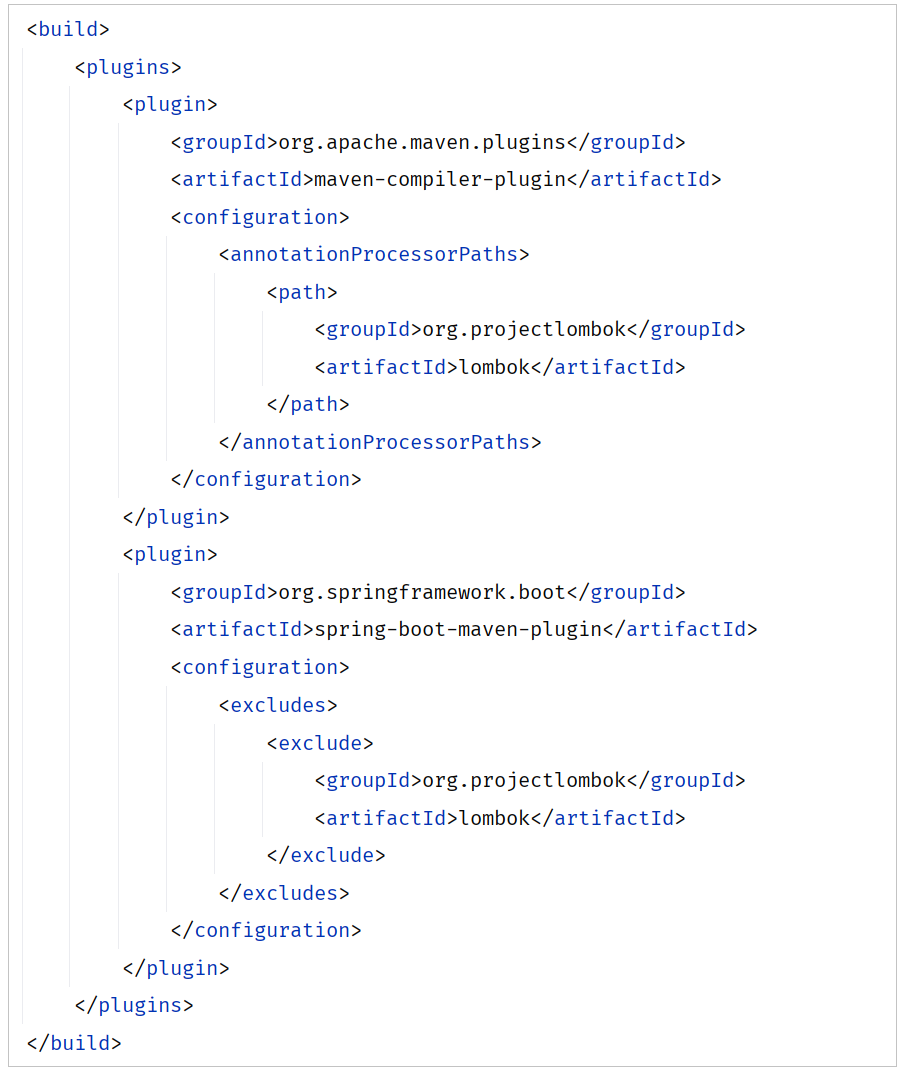

由于第一个插件 maven-compiler-plugin 的引入导致了这个问题，解决这个问题的方案呢，就是直接将第一个插件删除即可。

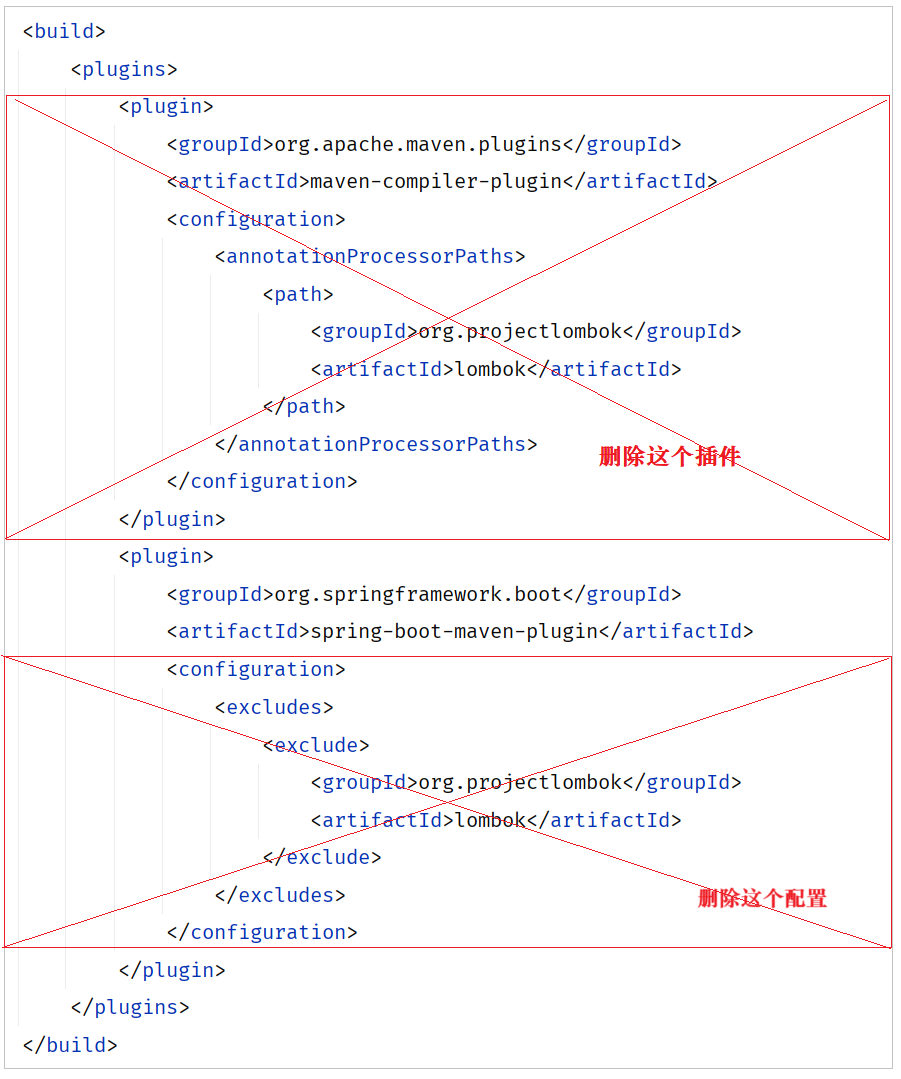

否则，可能就会出现406问题，或者程序运行时出现如下错误：

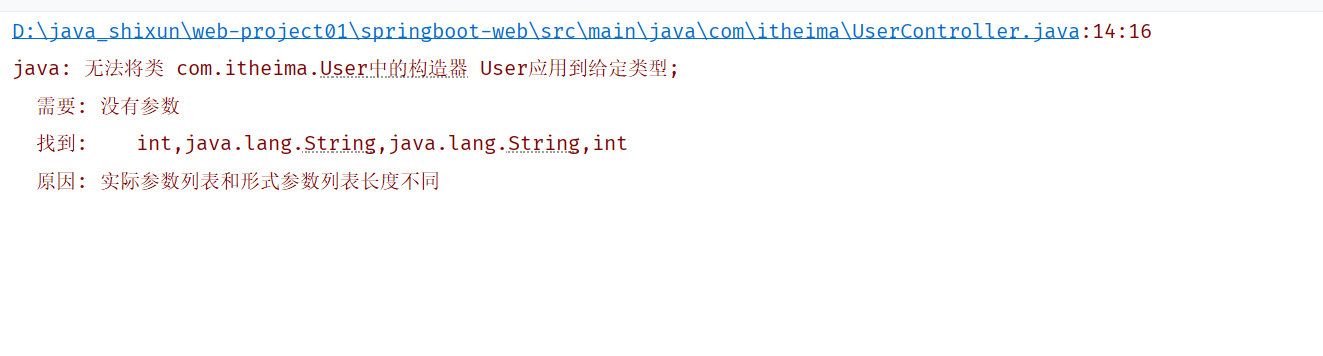

<strong>记得：pom.xml配置文件一旦变动，记得重新加载，然后把整个项目clean一下，然后再执行。</strong>

<strong>记得：pom.xml配置文件一旦变动，记得重新加载，然后把整个项目clean一下，然后再执行。</strong>

<strong>记得：pom.xml配置文件一旦变动，记得重新加载，然后把整个项目clean一下，然后再执行。</strong>


附录的“直接删除 maven-compiler-plugin”仅是原作者遇到的一种项目配置情形，不是通用 406 修复。若请求使用 `Accept: application/xml` 而接口只提供 JSON，应改为可接受的媒体类型；若代码编译不通过，应先解决编译错误。两种问题需要分别验证。

补充核对资料：[Spring MVC 内容协商](https://docs.spring.io/spring-framework/reference/web/webmvc/mvc-config/content-negotiation.html)、[Spring MVC HTTP 消息转换器](https://docs.spring.io/spring-framework/reference/web/webmvc/message-converters.html)、[MyBatis Spring Boot Starter 版本兼容](https://mybatis.org/spring-boot-starter/mybatis-spring-boot-autoconfigure/)、[Nginx location 规则](https://nginx.org/en/docs/http/ngx_http_core_module.html#location)。本章示例中的版本用于课程复现，不表示当前最新版本。


**面试提示**：描述一次 `DELETE /depts?id=2` 请求时，先说明 Nginx 如何处理 `/api` 前缀，再说明 `@RequestParam` 绑定、Service 判断影响行数、Mapper 的 `#{id}` 参数绑定，以及成功或不存在时的 HTTP 状态和 `Result`。若遇 406，先检查 `Accept` 和响应表示，不能把它直接等同于编译插件故障。
